# Transfer Learning with ResNet50 and MaxViT-Tiny in Three Scenarios
## Class-imbalance handling (before / after) + 10-fold cross-validation on Pakistani vehicles and Stanford Cars

**Deep Learning assignment (Dr Atif Tahir).**
Two ImageNet-pretrained models (ResNet50 = CNN, MaxViT-Tiny = CNN + Transformer hybrid) are fine-tuned and tested in three scenarios:

| Scenario | Train on | Test on | Evaluation |
|---|---|---|---|
| **1** | Stanford Cars (public, 196 classes) | Private Pakistani vehicles, **make level** (shared makes only) | One run per model (domain shift) |
| **2** | Private dataset only (merged train+test pool) | Held-out folds of the private dataset | 10-fold stratified CV |
| **3** | Public + private together (class labels not merged) | Held-out folds of the combined set | 10-fold stratified CV |

**Metrics:** Accuracy, F1 (macro and weighted), AUC (one-vs-rest, macro), plus balanced accuracy, precision and recall.
For the CV scenarios we report the per-fold **mean ± std** and the **pooled out-of-fold** value.

**Contents:** 0 Setup · 1 Public data · 2 Private data · 3 Shared makes + leakage check · 4 Shared utilities · 5 Metrics · 6 Scenario 1 · 7 Scenario 2 · 8 Scenario 3 · 9 Final results

> **How to run:** set `FAST_DEBUG = True` in the config cell first (about 2 folds, 2 epochs, small subset) to test everything quickly.
> Then set it to `False`. To fit Kaggle's session limit, run one model per session with `RUN_ARCHS = ["resnet50"]`, then `["maxvit_t"]`.
> With `RESUME = True`, finished folds are skipped when you re-run.

---
## 0. Setup and configuration

In [1]:
%pip install -q albumentations safetensors

import os, sys, re, json, random, time, zipfile, shutil, warnings, hashlib, math
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from scipy.io import loadmat
from scipy.fft import dctn

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, confusion_matrix, classification_report)
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# =====================================================================
#                       CONFIG  (edit only this cell)
# =====================================================================
ON_KAGGLE = Path("/kaggle/working").is_dir()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("outputs")
WORK.mkdir(parents=True, exist_ok=True)

# ---------------- paths ----------------
PRIVATE_ROOT = "/kaggle/input/datasets/muhammadghulamabbas/vehicle/hj3vvx5946-1/Splited_dataset"
PUBLIC_ROOT = ""            # "" = auto-search SEARCH_ROOTS for Stanford Cars. Or give the exact folder.
SEARCH_ROOTS = ["/kaggle/input"] + ([] if ON_KAGGLE else ["."])
WEIGHT_SEARCH_ROOTS = ["/kaggle/input", os.path.expanduser("~/.cache/torch"), "."]
WEIGHT_HINTS = {"resnet50": "", "maxvit_t": ""}      # optional: exact path of a torchvision .pth file

# ---------------- what to run ----------------
ARCHS = ["resnet50", "maxvit_t"]
RUN_ARCHS = ["resnet50", "maxvit_t"]    # run ONE model per Kaggle session if time is short, e.g. ["resnet50"]
SCENARIOS_TO_RUN = [1, 2, 3]
N_FOLDS = 10
VAL_FRACTION = 0.15                      # share of each training part used for validation / early stopping
STAGE1_EPOCHS = 5                        # stage 1: new head only
STAGE2_EPOCHS = 15                       # stage 2: head + upper backbone, early stopping
MAX_PER_CLASS = None                     # e.g. 60: random cap per class (before splitting) to cut compute
RESUME = True                            # skip folds / runs whose results are already saved
CROP_TO_BBOX = False                     # Stanford Cars: crop each image to its annotated bounding box
FAST_DEBUG = False                       # True: 2 folds, 2 epochs, tiny subset (quick test). Normally leave False.
SMOKE_TEST_FIRST = True                  # True: before the real run, execute this whole notebook once in FAST_DEBUG mode
                                         # (child process). If anything crashes you see it in minutes, not hours.
SMOKE_CHILD = os.environ.get("NB_SMOKE_CHILD") == "1"     # set automatically inside the smoke-test child process
if SMOKE_CHILD:
    FAST_DEBUG = True

# ---------------- data rules ----------------
MIN_IMAGES_PER_CLASS = 10                # classes with fewer images are listed and dropped (no crash)
PHASH_MAX_DISTANCE = 4                   # Hamming distance (<=) for a "near duplicate"
DROP_WITHIN_DUPLICATES = False           # True: also remove near-duplicates inside one dataset (default: only report)
CACHE_IMAGES = True                      # store smaller copies of the images (much faster decoding)
CACHE_MAX_SIDE = 320

# ---------------- make-name normalisation (EDITABLE) ----------------
# key = make as it appears in a class name (lower case), value = the cleaned make.
MAKE_NORMALISE = {
    "daiatsu": "daihatsu",      # spelling mistake in the private data
    "kyber": "khyber",
    "toyata": "toyota",
    "suzuky": "suzuki",
    "mercedes": "mercedes-benz",
    "chevy": "chevrolet",
    "vw": "volkswagen",
}
# makes that consist of several words (a class name starting with these keeps both words as the make)
MULTIWORD_MAKES = ["am general", "aston martin", "land rover", "alfa romeo", "rolls royce", "mercedes benz"]

# ---------------- reproducibility / images ----------------
SEED = 42
IMAGE_SIZE = 224          # MaxViT-Tiny needs 224
BATCH_SIZE = 32           # use 16 if MaxViT runs out of GPU memory
NUM_WORKERS = min(4, os.cpu_count() or 2)
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

# ---------------- training (shared) ----------------
DROPOUT = 0.3
LABEL_SMOOTHING = 0.1
PATIENCE = 4
CLIP_NORM = 1.0
HP = {
    "resnet50": dict(lr_stage1=1e-3, lr_backbone=1e-4, lr_head=5e-4, weight_decay=1e-4),
    "maxvit_t": dict(lr_stage1=5e-4, lr_backbone=5e-5, lr_head=5e-4, weight_decay=1e-2),
}

# ---------------- FAST_DEBUG overrides ----------------
DEBUG_CLASSES_PER_MAKE, DEBUG_MAX_PER_CLASS = 2, 8
if FAST_DEBUG:
    N_FOLDS, STAGE1_EPOCHS, STAGE2_EPOCHS = 2, 1, 1
    MIN_IMAGES_PER_CLASS = 2
    print("*** FAST_DEBUG is ON: 2 folds, 2 epochs, small subset. Results go to a separate folder. ***")

RES = WORK / ("results_debug" if FAST_DEBUG else "results")      # all saved results of this run
FIG_DIR = RES / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
assert set(RUN_ARCHS) <= set(ARCHS), "RUN_ARCHS must be a subset of ARCHS"
assert not CROP_TO_BBOX or CACHE_IMAGES, "CROP_TO_BBOX needs CACHE_IMAGES = True (the crop is done while caching)"
print(f"device={DEVICE} | torch={torch.__version__} | albumentations={A.__version__} | workers={NUM_WORKERS}")
print(f"RUN_ARCHS={RUN_ARCHS} | scenarios={SCENARIOS_TO_RUN} | folds={N_FOLDS} | epochs={STAGE1_EPOCHS}+{STAGE2_EPOCHS} "
      f"| MAX_PER_CLASS={MAX_PER_CLASS} | RESUME={RESUME} | CROP_TO_BBOX={CROP_TO_BBOX}")
print("results folder:", RES)
if DEVICE.type == "cpu":
    print("WARNING: no GPU found. Enable it in Kaggle: Session options -> Accelerator -> GPU.")

Note: you may need to restart the kernel to use updated packages.
device=cuda | torch=2.11.0+cu128 | albumentations=2.0.8 | workers=4
RUN_ARCHS=['resnet50', 'maxvit_t'] | scenarios=[1, 2, 3] | folds=10 | epochs=5+15 | MAX_PER_CLASS=None | RESUME=True | CROP_TO_BBOX=False
results folder: /kaggle/working/results


### 0.0 Smoke test first (automatic)
With `SMOKE_TEST_FIRST = True`, the cell below runs a **copy of this whole notebook in FAST_DEBUG mode** (2 folds, 2 epochs, tiny subset) in a child process.
If any section fails, the full run is never started and you see the error immediately. If it passes, the real run continues in this kernel.
The notebook file is found automatically (Kaggle saves it as `__notebook__.ipynb`). If it cannot be found, the cell tells you and you can set `FAST_DEBUG = True` by hand instead.

In [2]:
def run_smoke_test():
    import subprocess, glob
    names = ["/kaggle/working/__notebook__.ipynb", "/kaggle/working/__notebook_source__.ipynb"]
    names += glob.glob("/kaggle/working/*.ipynb") + glob.glob("/kaggle/src/*.ipynb") + glob.glob("*.ipynb")
    nb_path = None
    for cand in names:
        if "smoke_executed" in cand or not os.path.isfile(cand):
            continue
        try:
            txt = open(cand, encoding="utf-8").read()
        except Exception:
            continue
        if "run_smoke_test" in txt and "SMOKE_TEST_FIRST" in txt:
            nb_path = cand; break
    if nb_path is None:
        print("SMOKE TEST: notebook file not found, so it was NOT run automatically.\n"
              "  -> Set FAST_DEBUG = True in the config cell, run all cells, then set it back to False.")
        return
    print(f"SMOKE TEST: executing {nb_path} in FAST_DEBUG mode (child process) ...")
    t0 = time.time()
    cmd = [sys.executable, "-m", "jupyter", "nbconvert", "--to", "notebook", "--execute",
           "--ExecutePreprocessor.timeout=-1", "--output-dir", str(WORK), "--output", "smoke_executed", nb_path]
    r = subprocess.run(cmd, env=dict(os.environ, NB_SMOKE_CHILD="1"), capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stderr[-6000:])
        raise RuntimeError("SMOKE TEST FAILED (see the error above). The full run was NOT started. "
                           f"The executed copy with all outputs is at {WORK / 'smoke_executed.ipynb'}.")
    print(f"SMOKE TEST PASSED in {(time.time() - t0) / 60:.1f} min -> continuing with the FULL run.")


if SMOKE_TEST_FIRST and not FAST_DEBUG:
    run_smoke_test()

SMOKE TEST: executing /kaggle/working/__notebook__.ipynb in FAST_DEBUG mode (child process) ...
SMOKE TEST PASSED in 2.6 min -> continuing with the FULL run.


### 0.1 Reproducibility helpers and the transfer-learning guard
The notebook refuses to continue without real ImageNet weights (training from scratch would ruin the comparison).
A weights file is accepted only if it loads into the matching torchvision model with `strict=True`
(every tensor present, including the 1000-class ImageNet head). Only the models in `RUN_ARCHS` are checked.

If Internet is OFF on Kaggle, create the weight files once somewhere with Internet and attach them as a dataset:
```python
import torch
from torchvision import models
torch.save(models.resnet50(weights="DEFAULT").state_dict(), "resnet50_imagenet.pth")
torch.save(models.maxvit_t(weights="DEFAULT").state_dict(), "maxvit_t_imagenet.pth")
```

In [3]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def worker_init_fn(worker_id):
    np.random.seed(SEED + worker_id); random.seed(SEED + worker_id)


def make_generator(seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)
    return g


def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(FIG_DIR / name, dpi=130, bbox_inches="tight"); plt.show()


# ---------------- transfer-learning guard (from the original notebook) ----------------
ARCH_INFO = {
    "resnet50": dict(
        title="ResNet50", ctor=models.resnet50, enum="ResNet50_Weights",
        keywords=("resnet50", "resnet-50", "resnet_50"),
        frozen=("conv1.", "bn1.", "layer1.", "layer2."), tuned=("layer3.", "layer4."),
        stage2_text="layer3 + layer4 + new fc"),
    "maxvit_t": dict(
        title="MaxViT-Tiny", ctor=models.maxvit_t, enum="MaxVit_T_Weights",
        keywords=("maxvit",),
        frozen=("stem.", "blocks.0.", "blocks.1."), tuned=("blocks.2.", "blocks.3."),
        stage2_text="stages 3-4 (blocks.2, blocks.3) + new classifier"),
}
_STATE_CACHE = {}


def read_state_file(path):
    path = str(path)
    if path in _STATE_CACHE:
        return _STATE_CACHE[path]
    if path.lower().endswith(".safetensors"):
        from safetensors.torch import load_file
        state = load_file(path)
    else:
        try:
            state = torch.load(path, map_location="cpu", weights_only=True)
        except Exception:
            state = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(state, dict):
        for key in ("state_dict", "model_state_dict", "model"):
            if key in state and isinstance(state[key], dict):
                state = state[key]; break
    else:
        state = state.state_dict()
    state = {k.replace("module.", "", 1): v for k, v in state.items()}
    _STATE_CACHE[path] = state
    return state


def verify_imagenet_state(arch, state):
    try:
        ARCH_INFO[arch]["ctor"](weights=None).load_state_dict(state, strict=True)
        return True, "ok"
    except Exception as error:
        return False, f"{type(error).__name__}: {str(error)[:100]}"


def candidate_weight_files(arch):
    hint = WEIGHT_HINTS.get(arch, "")
    files = [hint] if hint and os.path.exists(hint) else []
    keywords = ARCH_INFO[arch]["keywords"]
    found = []
    for root in WEIGHT_SEARCH_ROOTS:
        if not os.path.isdir(root):
            continue
        for dirpath, _, names in os.walk(root):
            for name in names:
                full = os.path.join(dirpath, name)
                if (name.lower().endswith((".pth", ".pt", ".safetensors"))
                        and not name.startswith(("best_", "ckpt_"))
                        and full not in files and full not in found and os.path.getsize(full) < 600e6):
                    found.append(full)
    found.sort(key=lambda p: not any(k in p.lower() for k in keywords))
    return files + found


def locate_pretrained_state(arch):
    info = ARCH_INFO[arch]
    for path in candidate_weight_files(arch):
        try:
            state = read_state_file(path)
        except Exception:
            continue
        ok, message = verify_imagenet_state(arch, state)
        if ok:
            return state, f"local file: {path}"
        if any(k in path.lower() for k in info["keywords"]):
            print(f"  [{arch}] skip {path}: {message}")
    try:
        state = getattr(models, info["enum"]).DEFAULT.get_state_dict(progress=True)
        if verify_imagenet_state(arch, state)[0]:
            return state, "torchvision download (Internet)"
    except Exception as error:
        print(f"  [{arch}] download not possible: {type(error).__name__}")
    return None, None


PRETRAINED, missing = {}, []
for arch in RUN_ARCHS:
    state, source = locate_pretrained_state(arch)
    if state is None:
        missing.append(arch)
    else:
        PRETRAINED[arch] = (state, source)

if missing:
    raise RuntimeError(
        f"\n\nNO PRETRAINED WEIGHTS FOUND for: {', '.join(missing)} -> transfer learning is impossible, training is blocked.\n"
        "Fix with ONE of:\n"
        "  A) Session options -> Internet = ON (phone-verified account) -> re-run.\n"
        "  B) Create the .pth files with the snippet in the markdown above, upload them as a Kaggle Dataset,\n"
        "     Add Input to this notebook, re-run.\n")

print("=" * 78)
print("TRANSFER LEARNING: ENABLED")
for arch, (state, source) in PRETRAINED.items():
    print(f"  {ARCH_INFO[arch]['title']:12s}: {len(state)} tensors, {sum(v.numel() for v in state.values()):,} params | {source}")
print("=" * 78)

TRANSFER LEARNING: ENABLED
  ResNet50    : 320 tensors, 25,610,205 params | local file: /kaggle/input/models/muhammadghulamabbas/resnet50-imagenet/pytorch/default/1/resnet50-11ad3fa6.pth
  MaxViT-Tiny : 582 tensors, 31,020,096 params | local file: /kaggle/input/models/muhammadghulamabbas/maxvit-t-imagenet/pytorch/default/1/maxvit_t-bc5ab103.pth


### 0.2 Helper functions: finding the private data, make names, image cache, runtime estimate

In [4]:
# ---------------- locate the private dataset ----------------
def find_split_dir(data_root):
    path = Path(data_root)
    if path.is_dir() and (path / "train").is_dir():
        return path
    if (path / "Splited_dataset").is_dir():
        return path / "Splited_dataset"
    for base in SEARCH_ROOTS:
        for dirpath, dirnames, _ in os.walk(base):
            if "Splited_dataset" in dirnames:
                return Path(dirpath) / "Splited_dataset"
    raise FileNotFoundError("Private 'Splited_dataset' folder not found. Check PRIVATE_ROOT / attach the dataset via Add Input.")


PRIV_SPLIT_DIR = find_split_dir(PRIVATE_ROOT)
print("private dataset folder:", PRIV_SPLIT_DIR)


# ---------------- make names ----------------
def derive_make(class_name):
    """First word of the class name (or a known multi-word make), lower case, then cleaned with MAKE_NORMALISE."""
    text = re.sub(r"[_\s]+", " ", str(class_name)).strip().lower()
    make = None
    for mw in MULTIWORD_MAKES:
        if text == mw or text.startswith(mw + " "):
            make = mw; break
    if make is None:
        make = text.split(" ")[0] if text else "unknown"
    return MAKE_NORMALISE.get(make, make)


# ---------------- image cache (smaller copies, optional bbox crop) ----------------
CACHE_DIR = WORK / f"img_cache_{'crop' if CROP_TO_BBOX else 'full'}_{CACHE_MAX_SIDE}"


def _cache_one(args):
    src, bbox = args
    dst = CACHE_DIR / (hashlib.md5(src.encode()).hexdigest() + ".jpg")
    if dst.exists():
        return str(dst)
    try:
        with Image.open(src) as im:
            if bbox is None:
                im.draft("RGB", (CACHE_MAX_SIDE, CACHE_MAX_SIDE))    # fast JPEG decoding at reduced size
            im = im.convert("RGB")
            if bbox is not None:
                x1, y1, x2, y2 = bbox
                W, H = im.size
                im = im.crop((max(0, x1), max(0, y1), min(W, x2), min(H, y2)))
            im.thumbnail((CACHE_MAX_SIDE, CACHE_MAX_SIDE), Image.BICUBIC)
            im.save(dst, "JPEG", quality=95)
        return str(dst)
    except Exception:
        return None


def prepare_images(df, desc):
    """Adds the 'path' column used everywhere else. Unreadable images are dropped and counted."""
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    use_box = CROP_TO_BBOX and "bx1" in df.columns and df["bx1"].notna().any()
    args = []
    for row in df.itertuples():
        bbox = None
        if use_box and not np.isnan(row.bx1):
            bbox = (int(row.bx1), int(row.by1), int(row.bx2), int(row.by2))
        args.append((row.orig_path, bbox))
    if CACHE_IMAGES:
        with ThreadPoolExecutor(max_workers=max(2, NUM_WORKERS)) as ex:
            out = list(tqdm(ex.map(_cache_one, args), total=len(args), desc=f"caching {desc}"))
    else:
        out = [p if _readable(p) else None for p, _ in tqdm(args, desc=f"checking {desc}")]
    df = df.copy(); df["path"] = out
    bad = int(df["path"].isna().sum())
    if bad:
        print(f"  {desc}: {bad} unreadable images dropped")
    return df[df["path"].notna()].reset_index(drop=True)


def _readable(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False


def cap_per_class(df, cap, seed=SEED):
    """Random cap of `cap` images per class (done before any split). cap=None/0 -> unchanged."""
    if not cap:
        return df.reset_index(drop=True)
    rng = np.random.RandomState(seed); keep = []
    for _, g in df.groupby("label"):
        idx = g.index.values
        keep.extend(rng.choice(idx, size=min(len(idx), cap), replace=False))
    return df.loc[sorted(keep)].reset_index(drop=True)


def debug_subset(df):
    """FAST_DEBUG only: a few classes per make, few images per class."""
    chosen = []
    for _, labs in df.groupby("make")["label"].unique().items():
        chosen += sorted(labs)[:DEBUG_CLASSES_PER_MAKE]
    return cap_per_class(df[df["label"].isin(chosen)].reset_index(drop=True), DEBUG_MAX_PER_CLASS)


# ---------------- runtime estimate ----------------
THROUGHPUT = {"resnet50": 300.0, "maxvit_t": 100.0}   # ASSUMED training images/second on a Kaggle T4 with AMP (edit if you know better)
SESSION_LIMIT_H = 11.0                                 # Kaggle GPU sessions last about 12 h; keep a safety margin


def est_minutes(arch, n_train, n_val, n_test):
    thr = THROUGHPUT[arch]
    full_epochs = 0.6 * STAGE1_EPOCHS + 0.75 * STAGE2_EPOCHS        # stage 1 is cheaper, early stopping ends ~75 % of stage 2
    eval_epochs = STAGE1_EPOCHS + 0.75 * STAGE2_EPOCHS
    sec = full_epochs * n_train / thr + eval_epochs * n_val / (3 * thr) + n_test / (3 * thr) + 30
    return sec / 60.0


def runtime_plan(n_pub, n_priv, n_s1_test=None, n_s3_extra=None, title="ESTIMATED RUNTIME"):
    """n_pub / n_priv = images in each pool. Prints a table and warns if it will not fit one session."""
    vf, rows = VAL_FRACTION, []
    n_s1_test = n_priv if n_s1_test is None else n_s1_test
    n_s3 = n_pub + (n_priv if n_s3_extra is None else n_s3_extra)
    for arch in RUN_ARCHS:
        s1 = est_minutes(arch, n_pub * (1 - vf), n_pub * vf, n_s1_test)
        te = n_priv / N_FOLDS
        s2 = N_FOLDS * est_minutes(arch, (n_priv - te) * (1 - vf), (n_priv - te) * vf, te)
        te3 = n_s3 / N_FOLDS
        s3 = N_FOLDS * est_minutes(arch, (n_s3 - te3) * (1 - vf), (n_s3 - te3) * vf, te3)
        rows.append(dict(model=ARCH_INFO[arch]["title"], S1_min=s1 if 1 in SCENARIOS_TO_RUN else 0,
                         S2_min=s2 if 2 in SCENARIOS_TO_RUN else 0, S3_min=s3 if 3 in SCENARIOS_TO_RUN else 0))
    plan = pd.DataFrame(rows); plan["total_h"] = plan[["S1_min", "S2_min", "S3_min"]].sum(1) / 60
    print("=" * 78); print(title)
    display(plan.round(1))
    total = plan["total_h"].sum()
    print(f"TOTAL for RUN_ARCHS={RUN_ARCHS}: about {total:.1f} hours (rough: assumed speeds {THROUGHPUT} img/s, a Kaggle T4)")
    print("The real time per fold is printed during training together with a refreshed ETA.")
    if (plan["total_h"] > SESSION_LIMIT_H).any() or total > SESSION_LIMIT_H:
        print(f"WARNING: this may not fit into one Kaggle session (~{SESSION_LIMIT_H:.0f} h usable). Options: run one model per session "
              "(RUN_ARCHS), set MAX_PER_CLASS (e.g. 60), lower N_FOLDS / STAGE2_EPOCHS, and keep RESUME = True.")
    print("=" * 78)
    return plan


def _quick_count(root, skip=(), skip_test=False):
    n = 0
    for dp, dn, fn in os.walk(root):
        if any(os.path.abspath(dp).startswith(s) for s in skip):
            dn[:] = []; continue
        rel = os.path.relpath(dp, root).lower().split(os.sep)
        if skip_test and any("test" in part for part in rel):
            continue
        n += sum(os.path.splitext(f)[1].lower() in IMAGE_EXTENSIONS for f in fn)
    return n


# ---- preliminary estimate from raw file counts (refined after the data is loaded) ----
try:
    n_priv_q = _quick_count(PRIV_SPLIT_DIR)
    skip_q = [os.path.abspath(str(PRIV_SPLIT_DIR)), os.path.abspath(str(WORK))]
    roots_q = [PUBLIC_ROOT] if PUBLIC_ROOT else SEARCH_ROOTS
    n_pub_q = sum(_quick_count(r, skip_q, skip_test=True) for r in roots_q if os.path.isdir(r))
    if FAST_DEBUG:
        print("FAST_DEBUG: tiny subset, expect only a few minutes.")
    else:
        print(f"Preliminary file counts: private ~{n_priv_q:,} images, public ~{n_pub_q:,} images (test folder excluded)")
        _ = runtime_plan(n_pub_q, n_priv_q, title="PRELIMINARY RUNTIME ESTIMATE (refined in section 3 once the data is loaded)")
except Exception as error:
    print("Preliminary runtime estimate skipped:", type(error).__name__, error)

private dataset folder: /kaggle/input/datasets/muhammadghulamabbas/vehicle/hj3vvx5946-1/Splited_dataset
Preliminary file counts: private ~3,847 images, public ~8,144 images (test folder excluded)
PRELIMINARY RUNTIME ESTIMATE (refined in section 3 once the data is loaded)


,model,S1_min,S2_min,S3_min,total_h
0,ResNet50,6.4,29.9,82.7,2.0
1,MaxViT-Tiny,18.3,79.8,238.1,5.6


TOTAL for RUN_ARCHS=['resnet50', 'maxvit_t']: about 7.6 hours (rough: assumed speeds {'resnet50': 300.0, 'maxvit_t': 100.0} img/s, a Kaggle T4)
The real time per fold is printed during training together with a refreshed ETA.


---
## 1. Public dataset (Stanford Cars): discover, analyse, balance

**Layout detection.** The code looks for (a) the official devkit (`cars_meta.mat`, `cars_train_annos.mat`, optional `cars_test_annos_withlabels*.mat`,
images in `cars_train` / `cars_test`), and otherwise (b) class folders. The test annotations may have no labels, so we use **every labelled image**
and make our own splits. The official train/test split is ignored.

In [5]:
def walk_files(roots, skip=()):
    out = []
    for base in roots:
        if not os.path.isdir(base):
            continue
        for dp, dn, fn in os.walk(base):
            if any(os.path.abspath(dp).startswith(s) for s in skip):
                dn[:] = []; continue
            out.extend(os.path.join(dp, f) for f in fn)
    return out


def _is_img(f):
    return os.path.splitext(f)[1].lower() in IMAGE_EXTENSIONS


def read_annos(path):
    a = np.atleast_1d(loadmat(path, squeeze_me=True)["annotations"])
    fields = a.dtype.names or ()
    if "class" not in fields:
        return None                                     # unlabelled test annotations
    df = pd.DataFrame({"fname": [str(x) for x in a["fname"]], "cls": np.asarray(a["class"]).astype(int)})
    for src, dst in (("bbox_x1", "bx1"), ("bbox_y1", "by1"), ("bbox_x2", "bx2"), ("bbox_y2", "by2")):
        df[dst] = np.asarray(a[src]).astype(float) if src in fields else np.nan
    return df


def load_stanford_devkit(files, roots):
    mats = {f: os.path.basename(f).lower() for f in files if f.lower().endswith(".mat")}
    meta = next((f for f, b in mats.items() if b == "cars_meta.mat"), None)
    train_annos = [f for f, b in mats.items() if b == "cars_train_annos.mat"]
    test_annos = [f for f, b in mats.items() if b.startswith("cars_test_annos_withlabels")]
    if meta is None or not train_annos:
        return None
    names = [str(x) for x in np.atleast_1d(loadmat(meta, squeeze_me=True)["class_names"])]
    # index images by split (train / test) using the folder names, because file names repeat (00001.jpg) in both splits
    idx = {"train": {}, "test": {}}; anywhere = defaultdict(list)
    for f in files:
        if not _is_img(f):
            continue
        root = next((r for r in roots if f.startswith(r)), "")
        parts = [p.lower() for p in os.path.relpath(f, root).split(os.sep)[:-1]] if root else []
        is_tr, is_te = any("train" in p for p in parts), any("test" in p for p in parts)
        base = os.path.basename(f)
        if is_tr and not is_te: idx["train"][base] = f
        elif is_te and not is_tr: idx["test"][base] = f
        anywhere[base].append(f)
    parts_df, used = [], {"meta": meta}
    for split, annos_list in (("train", train_annos), ("test", test_annos)):
        if not annos_list:
            continue
        annos = read_annos(annos_list[0])
        if annos is None:
            print(f"  {os.path.basename(annos_list[0])}: no class labels -> skipped"); continue
        if annos["cls"].min() >= 1:
            annos["cls"] = annos["cls"] - 1                    # devkit labels are 1-based
        annos["orig_path"] = [idx[split].get(fn) or (anywhere[fn][0] if len(anywhere[fn]) == 1 else None) for fn in annos["fname"]]
        n_missing = int(annos["orig_path"].isna().sum())
        if n_missing > 0.05 * len(annos):
            raise FileNotFoundError(f"{n_missing}/{len(annos)} '{split}' images from the annotations were not found on disk.")
        annos = annos[annos["orig_path"].notna()].copy()
        annos["label"] = [names[c] for c in annos["cls"]]
        annos["split_orig"] = split
        parts_df.append(annos[["orig_path", "label", "split_orig", "bx1", "by1", "bx2", "by2"]])
        used[f"{split}_annos"] = annos_list[0]
        used[f"{split}_images_found"] = f"{len(annos)} (missing {n_missing})"
    return "devkit (.mat annotations)", pd.concat(parts_df, ignore_index=True), used


def load_stanford_folders(img_files):
    ignore = {"train", "test", "val", "valid", "validation", "images", "image", "cars_train", "cars_test", "data", "dataset"}
    rows = []
    for f in img_files:
        parent = os.path.basename(os.path.dirname(f))
        if parent.lower() in ignore:
            continue
        rows.append((f, parent.replace("_", " ").strip()))
    df = pd.DataFrame(rows, columns=["orig_path", "label"])
    if df["label"].nunique() < 50:
        return None
    df["split_orig"] = "folders"
    for c in ("bx1", "by1", "bx2", "by2"):
        df[c] = np.nan
    return "class folders", df.reset_index(drop=True), {"class_folders": int(df["label"].nunique())}


def load_public():
    roots = [PUBLIC_ROOT] if PUBLIC_ROOT else SEARCH_ROOTS
    skip = [os.path.abspath(str(PRIV_SPLIT_DIR)), os.path.abspath(str(WORK))]
    files = walk_files(roots, skip)
    img_files = [f for f in files if _is_img(f)]
    print(f"searched {roots}: {len(files):,} files, {len(img_files):,} images")
    result = load_stanford_devkit(files, roots) or load_stanford_folders(img_files)
    if result is None:
        raise FileNotFoundError("Stanford Cars not found. Attach it via Add Input or set PUBLIC_ROOT. "
                                "Expected cars_meta.mat + cars_train_annos.mat, or >= 50 class folders with images.")
    return result


layout, PUB, used_files = load_public()
print("\nSTANFORD CARS LAYOUT FOUND:", layout)
for k, v in used_files.items():
    print(f"  {k}: {v}")

PUB["source"] = "public"
PUB["make"] = PUB["label"].map(derive_make)
if FAST_DEBUG:
    PUB = debug_subset(PUB.reset_index(drop=True)); print("FAST_DEBUG subset of the public data:", len(PUB), "images")
PUB = prepare_images(PUB.reset_index(drop=True), "public")
print(f"\npublic: {PUB['label'].nunique()} classes, {len(PUB):,} labelled images (all labelled images used, own splits later)")

searched ['/kaggle/input']: 16,193 files, 16,185 images

STANFORD CARS LAYOUT FOUND: devkit (.mat annotations)
  meta: /kaggle/input/datasets/eduardo4jesus/stanford-cars-dataset/car_devkit/devkit/cars_meta.mat
  train_annos: /kaggle/input/datasets/eduardo4jesus/stanford-cars-dataset/car_devkit/devkit/cars_train_annos.mat
  train_images_found: 8144 (missing 0)


caching public:   0%|          | 0/8144 [00:00<?, ?it/s]


public: 196 classes, 8,144 labelled images (all labelled images used, own splits later)


### 1.1 Class distribution and imbalance
We compute the imbalance ratio (largest / smallest class) and the coefficient of variation (CV = std / mean, 0 = perfectly balanced).

**Balancing method (same as the original notebook).** A `WeightedRandomSampler` gives every training image the weight `1 / (images in its class)`,
so each class is drawn with equal probability. In addition, **class-aware Albumentations**: classes with fewer images than the median class get
the `strong` pipeline, the other classes the `standard` pipeline (test and validation images are never augmented).
The plot compares the natural per-epoch class counts (BEFORE) with the counts drawn by the balanced sampler (AFTER).
In the real experiments the sampler and the policy are computed again **inside each training part only**; here we show the whole pool just to illustrate the method.

Stanford Cars (public): 196 classes, 8,144 images | per class: min 24, max 68, mean 41.6
  smallest class: Hyundai Accent Sedan 2012 (24) | largest class: GMC Savana Van 2012 (68)


,BEFORE (natural),AFTER (balanced sampler)
classes,196.000,196.00
images,8144.000,8144.00
min,24.000,25.00
max,68.000,61.00
mean,41.550,41.55
median,42.000,41.00
imbalance_ratio,2.830,2.44
CV,0.104,0.17


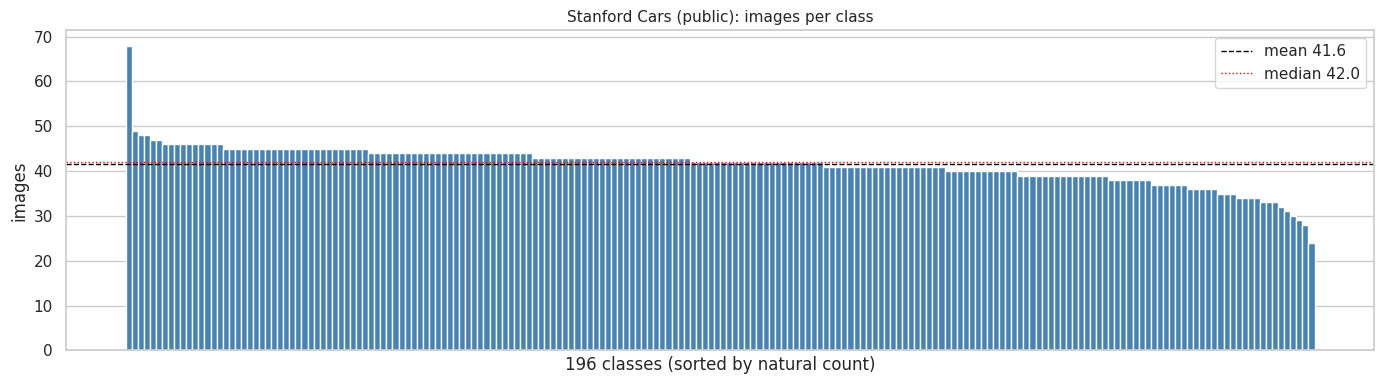

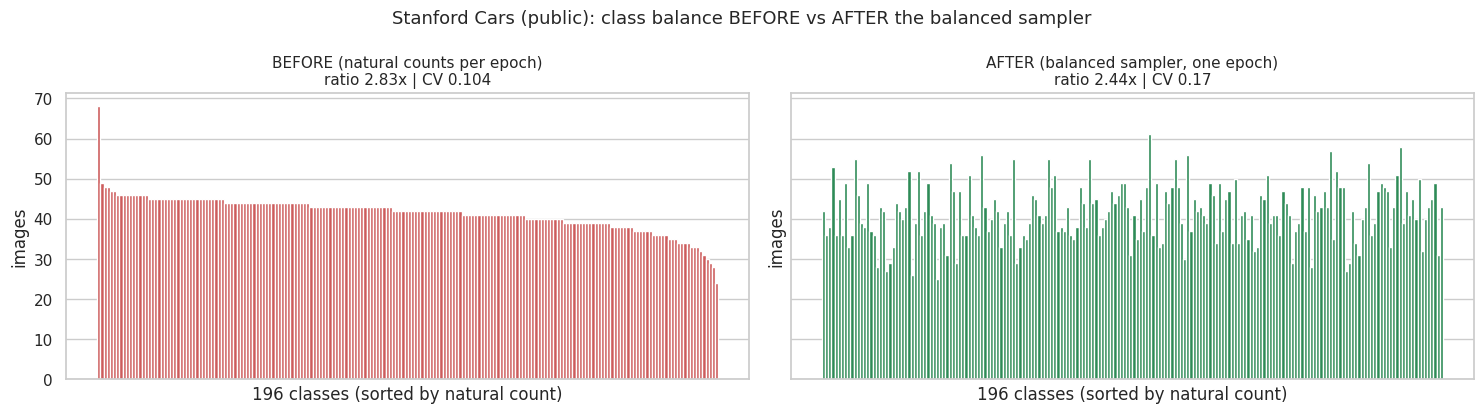

  class-aware augmentation: 81 minority classes (below the median) get 'strong', 115 get 'standard'.
  (Sampling is random with replacement, so the balanced counts vary a little around images/classes.)


In [6]:
def imbalance_stats(counts):
    c = np.asarray(counts, dtype=float)
    return dict(classes=len(c), images=int(c.sum()), min=int(c.min()), max=int(c.max()), mean=round(c.mean(), 2),
                median=float(np.median(c)), imbalance_ratio=round(c.max() / max(c.min(), 1), 2),
                CV=round(c.std() / c.mean(), 3))


def balanced_epoch_counts(label_ids, n_classes, seed=SEED):
    """Natural per-class counts and the counts of one epoch drawn by the balanced sampler."""
    natural = np.bincount(label_ids, minlength=n_classes)
    weights = 1.0 / natural[label_ids]
    sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double), num_samples=len(label_ids),
                                    replacement=True, generator=make_generator(seed))
    drawn = np.fromiter(iter(sampler), dtype=int)
    return natural, np.bincount(label_ids[drawn], minlength=n_classes)


def _bars(ax, values, names, order, color, title, small):
    if small:
        ax.barh(np.array(names)[order][::-1], np.asarray(values)[order][::-1], color=color); ax.set_xlabel("images")
    else:
        ax.bar(np.arange(len(order)), np.asarray(values)[order], color=color, width=1.0)
        ax.set_xticks([]); ax.set_xlabel(f"{len(order)} classes (sorted by natural count)"); ax.set_ylabel("images")
    ax.set_title(title, fontsize=11)


def plot_distribution(natural, names, title, fname):
    order = np.argsort(-natural); small = len(names) <= 60
    fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * len(names))) if small else (14, 4))
    _bars(ax, natural, names, order, "steelblue", title, small)
    line = ax.axvline if small else ax.axhline
    line(natural.mean(), ls="--", c="black", lw=1, label=f"mean {natural.mean():.1f}")
    line(np.median(natural), ls=":", c="red", lw=1, label=f"median {np.median(natural):.1f}")
    ax.legend(); save_fig(fig, fname)


def plot_before_after(natural, balanced, names, title, fname):
    order = np.argsort(-natural); small = len(names) <= 60
    s0, s1 = imbalance_stats(natural), imbalance_stats(balanced)
    fig, axes = plt.subplots(1, 2, figsize=(15, max(4, 0.3 * len(names))) if small else (15, 4.2), sharey=small is False)
    _bars(axes[0], natural, names, order, "indianred", f"BEFORE (natural counts per epoch)\nratio {s0['imbalance_ratio']}x | CV {s0['CV']}", small)
    _bars(axes[1], balanced, names, order, "seagreen", f"AFTER (balanced sampler, one epoch)\nratio {s1['imbalance_ratio']}x | CV {s1['CV']}", small)
    if small:
        axes[1].set_yticklabels([])
        lim = max(natural.max(), balanced.max()) * 1.05; axes[0].set_xlim(0, lim); axes[1].set_xlim(0, lim)
    fig.suptitle(title, fontsize=13)
    save_fig(fig, fname)


def analyse_and_balance(df, title, tag):
    codes, names = pd.factorize(df["label"], sort=True)
    natural, balanced = balanced_epoch_counts(codes, len(names))
    stats = pd.DataFrame({"BEFORE (natural)": imbalance_stats(natural), "AFTER (balanced sampler)": imbalance_stats(balanced)})
    print(f"{title}: {len(names)} classes, {len(df):,} images | per class: min {natural.min()}, max {natural.max()}, mean {natural.mean():.1f}")
    print(f"  smallest class: {names[natural.argmin()]} ({natural.min()}) | largest class: {names[natural.argmax()]} ({natural.max()})")
    display(stats)
    plot_distribution(natural, list(names), f"{title}: images per class", f"{tag}_class_distribution.png")
    plot_before_after(natural, balanced, list(names), f"{title}: class balance BEFORE vs AFTER the balanced sampler", f"{tag}_balancing_before_after.png")
    n_strong = int((natural < np.median(natural)).sum())
    print(f"  class-aware augmentation: {n_strong} minority classes (below the median) get 'strong', {len(names) - n_strong} get 'standard'.")
    print("  (Sampling is random with replacement, so the balanced counts vary a little around images/classes.)")
    stats.to_csv(RES / f"{tag}_imbalance_stats.csv")
    return stats


PUB_STATS = analyse_and_balance(PUB, "Stanford Cars (public)", "01_public")

### 1.2 Make of every public class
The make is the first word of the class name (multi-word makes such as Aston Martin, Land Rover, AM General are kept together; Rolls-Royce and Mercedes-Benz are single tokens).

In [7]:
pub_makes = PUB.groupby("make").agg(classes=("label", "nunique"), images=("label", "size")).sort_values("classes", ascending=False)
print(f"{len(pub_makes)} public makes, {pub_makes['classes'].sum()} classes")
display(pub_makes.T if len(pub_makes) > 25 else pub_makes)
print("\nExample class -> make:")
display(PUB.drop_duplicates("label")[["label", "make"]].head(8).reset_index(drop=True))
pub_makes.to_csv(RES / "01_public_classes_per_make.csv")

49 public makes, 196 classes


make,chevrolet,dodge,audi,bmw,ford,hyundai,chrysler,bentley,acura,mercedes-benz,...,geo,lincoln,ram,porsche,plymouth,mitsubishi,mini,smart,scion,tesla
classes,22,15,14,13,12,11,6,6,6,6,...,1,1,1,1,1,1,1,1,1,1
images,905,630,589,531,521,438,260,238,242,261,...,45,39,41,44,44,48,37,40,42,39



Example class -> make:


,label,make
0,Audi TTS Coupe 2012,audi
1,Acura TL Sedan 2012,acura
2,Dodge Dakota Club Cab 2007,dodge
3,Hyundai Sonata Hybrid Sedan 2012,hyundai
4,Ford F-450 Super Duty Crew Cab 2012,ford
5,Geo Metro Convertible 1993,geo
6,Dodge Journey SUV 2012,dodge
7,Dodge Charger Sedan 2012,dodge


---
## 2. Private dataset: same analysis
The original `train/` and `test/` folders are **merged into one pool**. All splits for the experiments are made by the notebook itself.
Classes below `MIN_IMAGES_PER_CLASS` are listed and dropped (nothing crashes).

In [8]:
def load_private():
    rows, class_names = [], set()
    for split in ("train", "test"):
        folder = PRIV_SPLIT_DIR / split
        if not folder.is_dir():
            print(f"  note: '{split}' folder missing in the private dataset"); continue
        for cdir in sorted(d for d in folder.iterdir() if d.is_dir() and not d.name.startswith(".")):
            class_names.add(cdir.name)
            for f in sorted(cdir.iterdir()):
                if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS:
                    rows.append((str(f), cdir.name, split))
    df = pd.DataFrame(rows, columns=["orig_path", "label", "split_orig"])
    for c in ("bx1", "by1", "bx2", "by2"):
        df[c] = np.nan
    return df


PRIV = load_private()
print(f"private (before checks): {PRIV['label'].nunique()} classes, {len(PRIV):,} images "
      f"(train folder {int((PRIV.split_orig == 'train').sum())} + test folder {int((PRIV.split_orig == 'test').sum())})")
PRIV["source"] = "private"
PRIV["make"] = PRIV["label"].map(derive_make)
if FAST_DEBUG:
    PRIV = debug_subset(PRIV.reset_index(drop=True)); print("FAST_DEBUG subset of the private data:", len(PRIV), "images")
PRIV = prepare_images(PRIV.reset_index(drop=True), "private")


def enforce_min_images(df, min_n, name):
    counts = df["label"].value_counts()
    print(f"{name}: smallest class = {counts.idxmin()} with {counts.min()} images (limit MIN_IMAGES_PER_CLASS = {min_n})")
    small = counts[counts < min_n]
    if len(small) == 0:
        print("  -> all classes meet the limit, nothing dropped."); return df
    print(f"  -> dropping {len(small)} classes, losing {int(small.sum())} images:")
    display(small.rename("images").to_frame())
    return df[~df["label"].isin(small.index)].reset_index(drop=True)


PRIV = enforce_min_images(PRIV, MIN_IMAGES_PER_CLASS, "private")
PUB = enforce_min_images(PUB, MIN_IMAGES_PER_CLASS, "public")     # same rule for the public data (nothing expected)

private (before checks): 48 classes, 3,847 images (train folder 3096 + test folder 751)


caching private:   0%|          | 0/3847 [00:00<?, ?it/s]

private: smallest class = Suzuki_carry with 16 images (limit MIN_IMAGES_PER_CLASS = 10)
  -> all classes meet the limit, nothing dropped.
public: smallest class = Hyundai Accent Sedan 2012 with 24 images (limit MIN_IMAGES_PER_CLASS = 10)
  -> all classes meet the limit, nothing dropped.


Private Pakistani vehicles: 48 classes, 3,847 images | per class: min 16, max 337, mean 80.1
  smallest class: Suzuki_carry (16) | largest class: Toyota_corolla_2016 (337)


,BEFORE (natural),AFTER (balanced sampler)
classes,48.000,48.000
images,3847.000,3847.000
min,16.000,59.000
max,337.000,98.000
mean,80.150,80.150
median,56.500,80.000
imbalance_ratio,21.060,1.660
CV,0.892,0.117


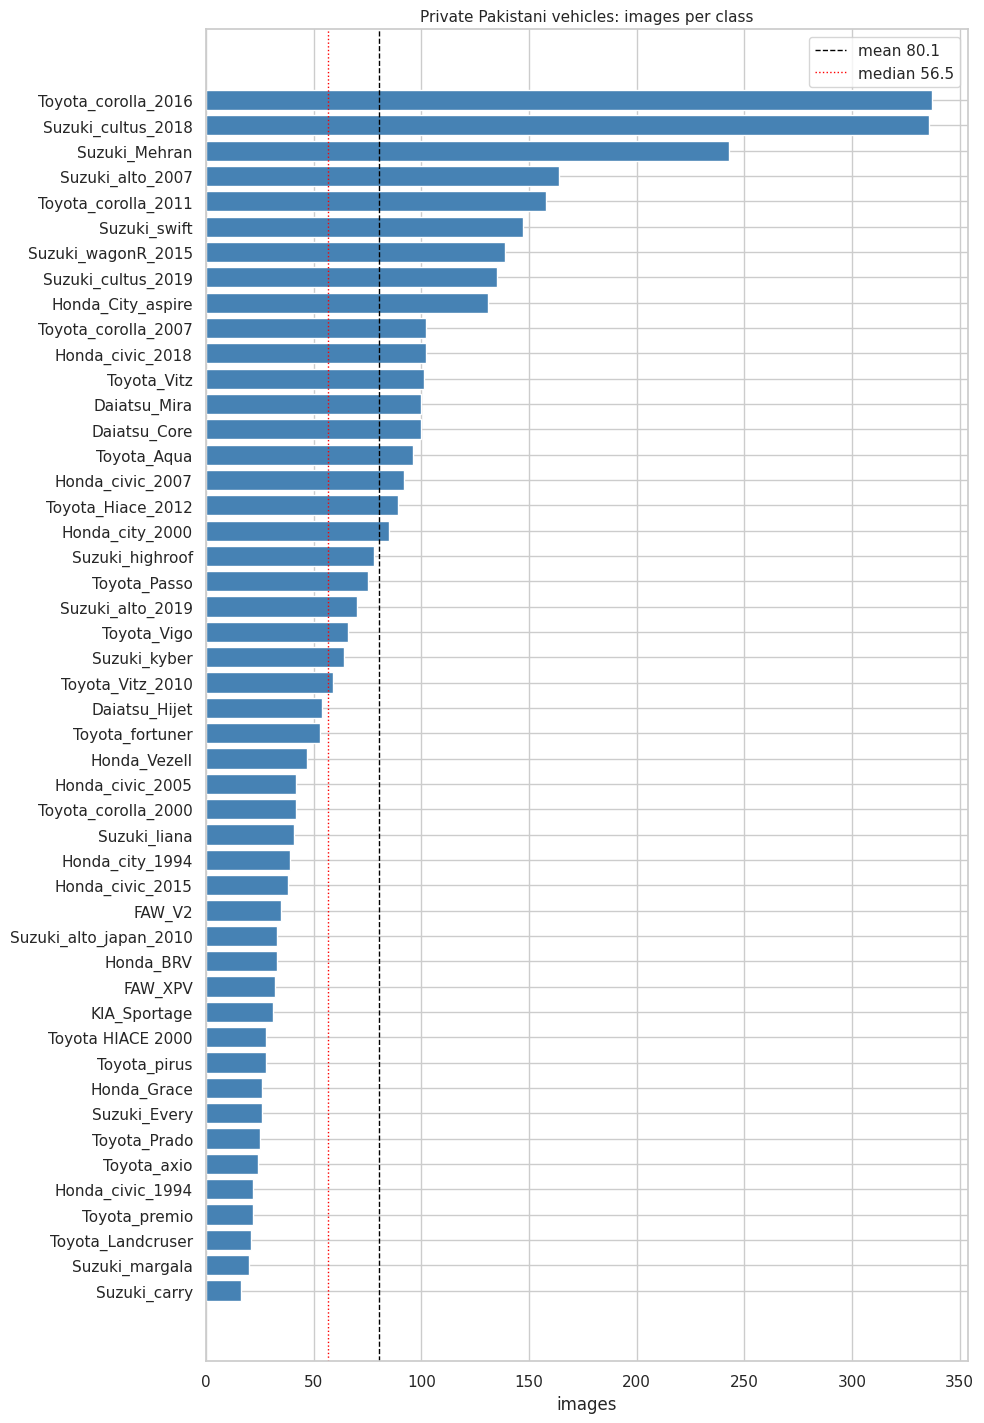

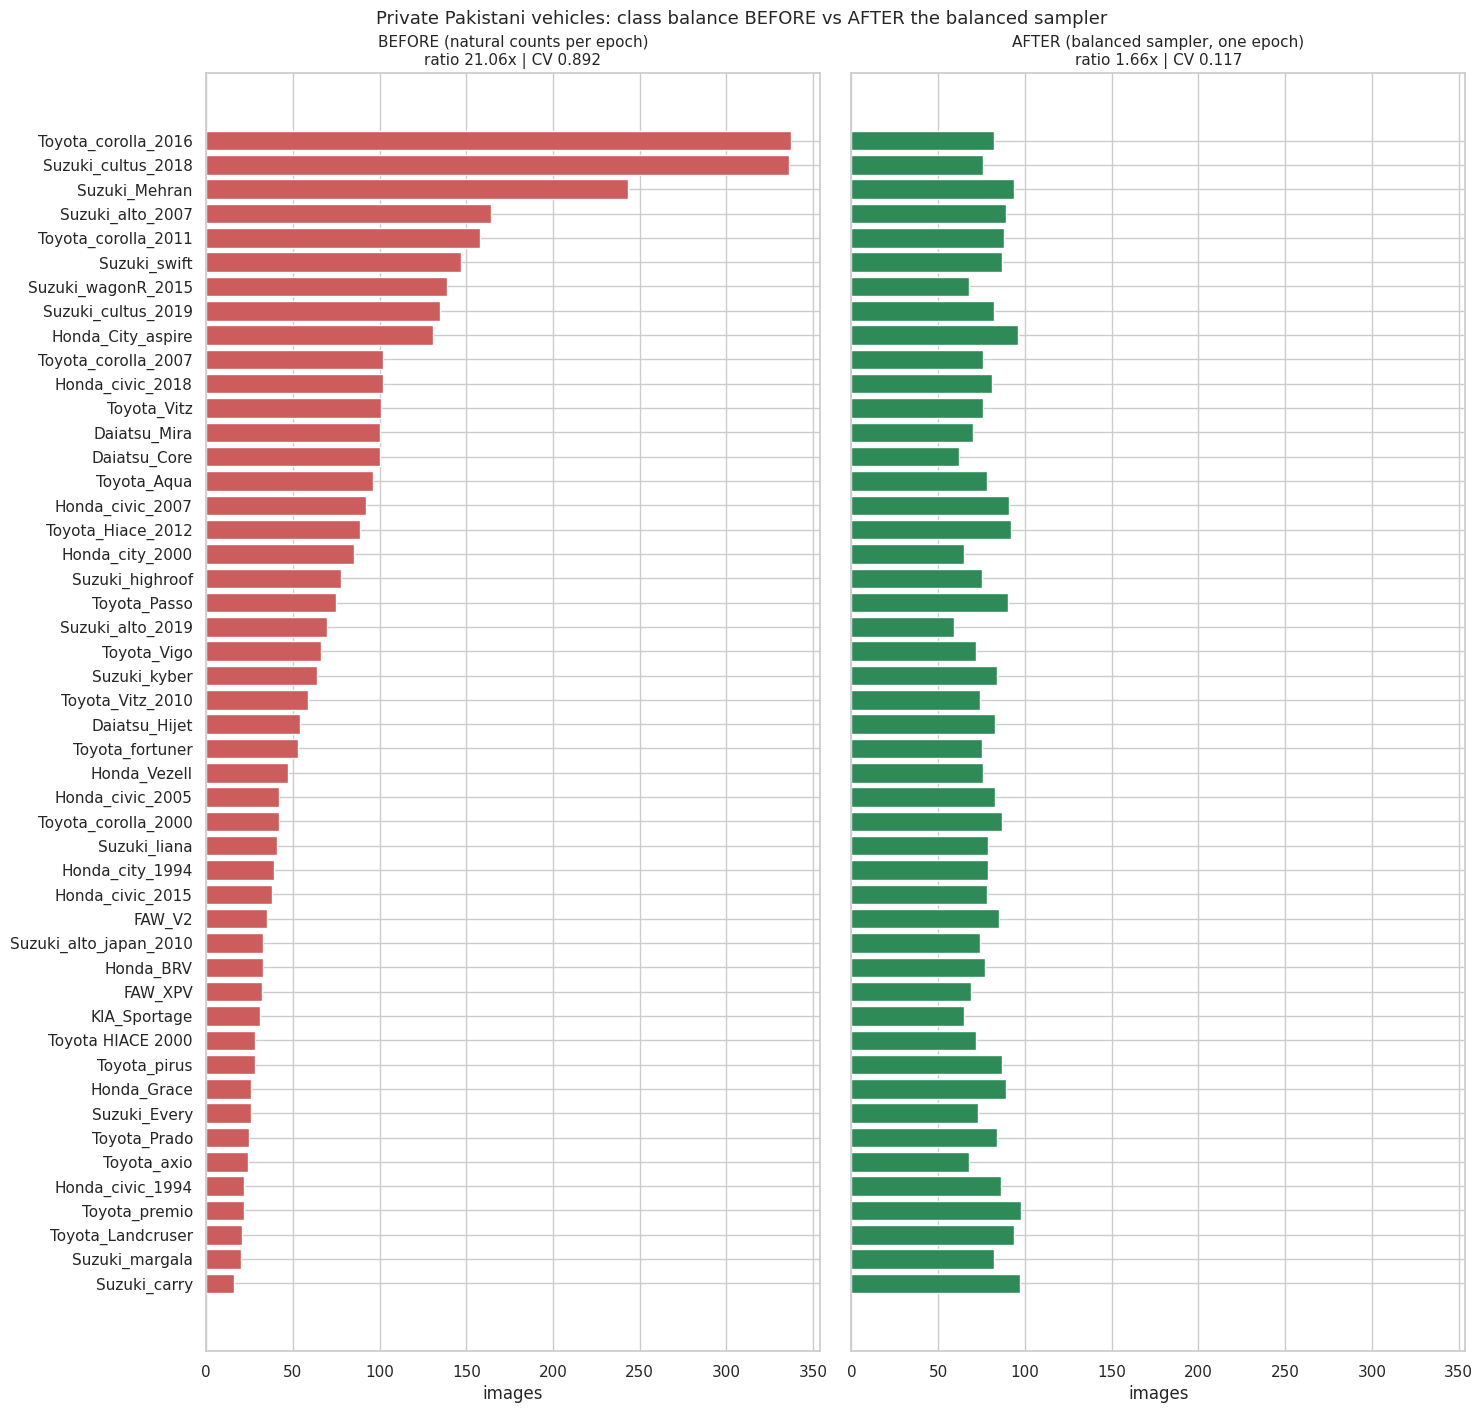

  class-aware augmentation: 24 minority classes (below the median) get 'strong', 24 get 'standard'.
  (Sampling is random with replacement, so the balanced counts vary a little around images/classes.)


In [9]:
PRIV_STATS = analyse_and_balance(PRIV, "Private Pakistani vehicles", "02_private")

### 2.1 Make of every private class
The make is the first word of the class name, cleaned by the editable `MAKE_NORMALISE` dictionary (config cell).
Check the table below: if two spellings of one make appear as separate rows, add them to the dictionary and re-run from the top.

In [10]:
priv_makes = PRIV.groupby("make").agg(classes=("label", "nunique"), images=("label", "size")).sort_values("images", ascending=False)
print(f"{len(priv_makes)} private makes, {priv_makes['classes'].sum()} classes, {priv_makes['images'].sum()} images")
display(priv_makes)
display(PRIV.drop_duplicates("label")[["label", "make"]].reset_index(drop=True).T if PRIV["label"].nunique() <= 12
        else PRIV.drop_duplicates("label")[["label", "make"]].reset_index(drop=True))
priv_makes.to_csv(RES / "02_private_classes_per_make.csv")

6 private makes, 48 classes, 3847 images


,classes,images
make,,
suzuki,14,1512
toyota,17,1326
honda,11,657
daihatsu,3,254
faw,2,67
kia,1,31


,label,make
0,Daiatsu_Core,daihatsu
1,Daiatsu_Hijet,daihatsu
2,Daiatsu_Mira,daihatsu
3,FAW_V2,faw
4,FAW_XPV,faw
5,Honda_BRV,honda
6,Honda_City_aspire,honda
7,Honda_Grace,honda
8,Honda_Vezell,honda
9,Honda_city_1994,honda


---
## 3. Shared makes and leakage check
### 3.1 Which makes do both datasets share?

In [11]:
pub_m = PUB.groupby("make").agg(public_classes=("label", "nunique"), public_images=("label", "size"))
priv_m = PRIV.groupby("make").agg(private_classes=("label", "nunique"), private_images=("label", "size"))
make_table = pub_m.join(priv_m, how="outer").fillna(0).astype(int)
make_table["status"] = np.where((make_table.public_images > 0) & (make_table.private_images > 0), "shared",
                                np.where(make_table.public_images > 0, "public-only", "private-only"))

SHARED_MAKES = sorted(make_table.index[make_table.status == "shared"])
PUBLIC_ONLY = sorted(make_table.index[make_table.status == "public-only"])
PRIVATE_ONLY = sorted(make_table.index[make_table.status == "private-only"])

print(f"SHARED makes ({len(SHARED_MAKES)}):")
display(make_table.loc[SHARED_MAKES, ["public_classes", "public_images", "private_classes", "private_images"]])
print(f"PRIVATE-ONLY makes ({len(PRIVATE_ONLY)}):")
display(make_table.loc[PRIVATE_ONLY, ["private_classes", "private_images"]])
print(f"PUBLIC-ONLY makes ({len(PUBLIC_ONLY)}), {int(make_table.loc[PUBLIC_ONLY, 'public_images'].sum()):,} public images:")
print("  " + ", ".join(f"{m} ({make_table.loc[m, 'public_images']})" for m in PUBLIC_ONLY))
n_priv_shared = int(PRIV["make"].isin(SHARED_MAKES).sum())
print(f"\nPrivate images in shared makes (Scenario 1 test set, before duplicate removal): {n_priv_shared}")
print(f"Private images in non-shared makes (reported separately, not scored): {len(PRIV) - n_priv_shared}")
make_table.to_csv(RES / "03_shared_makes.csv")
if not SHARED_MAKES:
    print("WARNING: no shared makes found -> Scenario 1 cannot run. Check MAKE_NORMALISE.")

SHARED makes (3):


,public_classes,public_images,private_classes,private_images
make,,,,
honda,4,161,11,657
suzuki,4,167,14,1512
toyota,4,168,17,1326


PRIVATE-ONLY makes (3):


,private_classes,private_images
make,,
daihatsu,3,254
faw,2,67
kia,1,31


PUBLIC-ONLY makes (46), 7,648 public images:
  acura (242), am general (45), aston martin (157), audi (589), bentley (238), bmw (531), bugatti (77), buick (158), cadillac (129), chevrolet (905), chrysler (260), daewoo (45), dodge (630), eagle (46), ferrari (164), fiat (62), fisker (44), ford (521), geo (45), gmc (238), hummer (83), hyundai (438), infiniti (67), isuzu (40), jaguar (47), jeep (220), lamborghini (161), land rover (86), lincoln (39), maybach (29), mazda (36), mclaren (44), mercedes-benz (261), mini (37), mitsubishi (48), nissan (171), plymouth (44), porsche (44), ram (41), rolls-royce (114), scion (42), smart (40), spyker (88), tesla (39), volkswagen (132), volvo (131)

Private images in shared makes (Scenario 1 test set, before duplicate removal): 3495
Private images in non-shared makes (reported separately, not scored): 352


### 3.2 Leakage check with perceptual hashes (pHash)
Every image gets a 64-bit pHash (DCT of a 32x32 grey image). Two images with a Hamming distance of 0 are exact (visual) duplicates, a distance <= `PHASH_MAX_DISTANCE` means near-duplicate.
We report duplicates **within** each dataset and **across** the two datasets. Cross-dataset duplicates are removed from the **private (test) side**
before any split, so the public images that train the model can never appear in the private test set.

In [12]:
def phash64(path, hash_size=8, factor=4):
    with Image.open(path) as im:
        im = im.convert("L").resize((hash_size * factor, hash_size * factor), Image.LANCZOS)
    dct = dctn(np.asarray(im, dtype=np.float64))[:hash_size, :hash_size]
    bits = (dct > np.median(dct)).ravel()
    return int(sum(1 << i for i, b in enumerate(bits) if b))


def compute_hashes(paths):
    cache_file = RES / "phash_cache.json"
    cache = json.loads(cache_file.read_text()) if (RESUME and cache_file.exists()) else {}
    todo = [p for p in paths if p not in cache]
    if todo:
        with ThreadPoolExecutor(max_workers=max(2, NUM_WORKERS)) as ex:
            for p, h in zip(todo, tqdm(ex.map(phash64, todo), total=len(todo), desc="pHash")):
                cache[p] = h
        cache_file.write_text(json.dumps(cache))
    return np.array([cache[p] for p in paths], dtype=np.uint64)


_M1, _M2, _M4, _H01 = (np.uint64(0x5555555555555555), np.uint64(0x3333333333333333),
                       np.uint64(0x0F0F0F0F0F0F0F0F), np.uint64(0x0101010101010101))


def popcount64(x):
    x = x - ((x >> np.uint64(1)) & _M1)
    x = (x & _M2) + ((x >> np.uint64(2)) & _M2)
    x = (x + (x >> np.uint64(4))) & _M4
    return ((x * _H01) >> np.uint64(56)).astype(np.int16)


def near_pairs(ha, hb=None, max_d=PHASH_MAX_DISTANCE, chunk=512):
    """All pairs (i, j, distance) with Hamming distance <= max_d. hb=None: pairs inside ha (i < j)."""
    same = hb is None
    hb = ha if same else hb
    out = []
    for s in range(0, len(ha), chunk):
        d = popcount64(ha[s:s + chunk, None] ^ hb[None, :])
        ii, jj = np.nonzero(d <= max_d)
        dd = d[ii, jj]; ii = ii + s
        if same:
            keep = jj > ii; ii, jj, dd = ii[keep], jj[keep], dd[keep]
        out.append(np.stack([ii, jj, dd], 1))
    return np.concatenate(out) if out else np.zeros((0, 3), int)


h_pub, h_priv = compute_hashes(PUB["path"].tolist()), compute_hashes(PRIV["path"].tolist())
pairs_pub, pairs_priv = near_pairs(h_pub), near_pairs(h_priv)
pairs_cross = near_pairs(h_pub, h_priv)          # i = public image, j = private image

rows = []
for name, pr, n in (("within public", pairs_pub, len(PUB)), ("within private", pairs_priv, len(PRIV)), ("across public <-> private", pairs_cross, None)):
    rows.append({"scope": name, "exact duplicate pairs (d=0)": int((pr[:, 2] == 0).sum()),
                 f"near-duplicate pairs (d<={PHASH_MAX_DISTANCE})": len(pr),
                 "images involved": len(set(pr[:, 0]) | set(pr[:, 1])) if name.startswith("within") else
                                    f"{len(set(pr[:, 0]))} public + {len(set(pr[:, 1]))} private"})
display(pd.DataFrame(rows))


def greedy_drop(pairs):
    dropped = set()
    for i, j, _ in pairs[np.lexsort((pairs[:, 1], pairs[:, 0]))] if len(pairs) else []:
        if i not in dropped and j not in dropped:
            dropped.add(int(j))
    return dropped


PUB_USE, PRIV_S2 = PUB, PRIV
if DROP_WITHIN_DUPLICATES:
    dp, dv = greedy_drop(pairs_pub), greedy_drop(pairs_priv)
    PUB_USE = PUB.drop(index=list(dp)).reset_index(drop=True)
    PRIV_S2 = PRIV.drop(index=list(dv)).reset_index(drop=True)
    print(f"DROP_WITHIN_DUPLICATES=True: removed {len(dp)} public and {len(dv)} private images that duplicate another image of the same dataset.")
else:
    print("Within-dataset duplicates are only reported (DROP_WITHIN_DUPLICATES=False). They can make CV scores slightly optimistic.")

cross_paths = set(PRIV.loc[sorted(set(pairs_cross[:, 1].tolist())), "path"]) if len(pairs_cross) else set()
PRIV_S13 = PRIV_S2[~PRIV_S2["path"].isin(cross_paths)].reset_index(drop=True)      # private pool for Scenario 1 and 3
removed = len(PRIV_S2) - len(PRIV_S13)
print(f"\nCross-dataset duplicates removed from the private (test) side: {removed} images "
      f"(Scenario 1 and 3 use the cleaned private set of {len(PRIV_S13)} images; Scenario 2 uses {len(PRIV_S2)}).")
S1_TEST_SIZE = int(PRIV_S13["make"].isin(SHARED_MAKES).sum())
print(f"Scenario 1 test set (private images of shared makes, after removal): {S1_TEST_SIZE}")

if len(pairs_cross):                              # show a few cross-dataset pairs
    show = pairs_cross[np.argsort(pairs_cross[:, 2])][:4]
    fig, axes = plt.subplots(len(show), 2, figsize=(7, 3.2 * len(show)), squeeze=False)
    for r, (i, j, d) in enumerate(show):
        axes[r, 0].imshow(Image.open(PUB.loc[i, "path"])); axes[r, 0].set_title(f"public: {PUB.loc[i, 'label']}", fontsize=8)
        axes[r, 1].imshow(Image.open(PRIV.loc[j, "path"])); axes[r, 1].set_title(f"private: {PRIV.loc[j, 'label']}  (d={d})", fontsize=8)
    for ax in axes.ravel():
        ax.axis("off")
    save_fig(fig, "03_cross_dataset_duplicates.png")
leak = pd.DataFrame(rows); leak.to_csv(RES / "03_leakage_report.csv", index=False)

pHash:   0%|          | 0/8144 [00:00<?, ?it/s]

pHash:   0%|          | 0/3847 [00:00<?, ?it/s]

,scope,exact duplicate pairs (d=0),near-duplicate pairs (d<=4),images involved
0,within public,14,17,34
1,within private,49,66,129
2,across public <-> private,0,0,0 public + 0 private


Within-dataset duplicates are only reported (DROP_WITHIN_DUPLICATES=False). They can make CV scores slightly optimistic.

Cross-dataset duplicates removed from the private (test) side: 0 images (Scenario 1 and 3 use the cleaned private set of 3847 images; Scenario 2 uses 3847).
Scenario 1 test set (private images of shared makes, after removal): 3495


### 3.3 Refined runtime estimate (exact image counts, MAX_PER_CLASS applied)

In [13]:
_pub_n = len(cap_per_class(PUB_USE, MAX_PER_CLASS))
_s2_n = len(cap_per_class(PRIV_S2, MAX_PER_CLASS))
_s3_n = len(cap_per_class(pd.concat([PUB_USE.assign(label="public|" + PUB_USE["label"]),
                                     PRIV_S13.assign(label="private|" + PRIV_S13["label"])], ignore_index=True), MAX_PER_CLASS))
print(f"Image counts used: Scenario 1 train {_pub_n} (public) / test {S1_TEST_SIZE} | Scenario 2 pool {_s2_n} | Scenario 3 pool {_s3_n}")
RUNTIME_PLAN = None
if FAST_DEBUG:
    print("FAST_DEBUG: tiny subset, expect a few minutes.")
else:
    # runtime_plan(n_pub, n_priv, ...): the Scenario 3 pool is passed as n_pub + n_s3_extra
    RUNTIME_PLAN = runtime_plan(_pub_n, _s2_n, n_s1_test=S1_TEST_SIZE, n_s3_extra=_s3_n - _pub_n,
                                title="ESTIMATED RUNTIME (exact counts)")

Image counts used: Scenario 1 train 8144 (public) / test 3495 | Scenario 2 pool 3847 | Scenario 3 pool 11991
ESTIMATED RUNTIME (exact counts)


,model,S1_min,S2_min,S3_min,total_h
0,ResNet50,6.4,29.9,82.7,2.0
1,MaxViT-Tiny,18.2,79.8,238.1,5.6


TOTAL for RUN_ARCHS=['resnet50', 'maxvit_t']: about 7.6 hours (rough: assumed speeds {'resnet50': 300.0, 'maxvit_t': 100.0} img/s, a Kaggle T4)
The real time per fold is printed during training together with a refreshed ETA.


---
## 4. Shared utilities
Everything below is used by all three scenarios, so every run gets the **same recipe, seed and pretrained weights**.

* **Albumentations** (`none` / `standard` / `strong`): `none` = resize + normalise only (validation and test, never augmented).
* **`build_loaders`**: the balanced sampler and the class-aware augmentation policy come **only from the training part passed in** (that fold's training images).
* **`split_train_val`**: stratified split that keeps at least 1 validation image per class (classes with a single image stay in training, no crash).
* **`train_one_run`**: two-stage transfer learning. Stage 1 trains the new head only (5 epochs). Stage 2 trains the head + upper backbone
  (ResNet50: `layer3`, `layer4`; MaxViT: `blocks.2`, `blocks.3`) for up to 15 epochs with early stopping. The best epoch is chosen by **validation macro-F1**.
  Frozen layers stay in `eval()` mode (fixed BatchNorm statistics). `verify_transfer` proves the frozen layers are bit-identical to ImageNet.
* **`evaluate`**: returns `y_true`, `y_pred` and softmax probabilities.

In [14]:
# ---------------- Albumentations pipelines (from the original notebook) ----------------
def build_pipeline(level):
    resize = [A.Resize(IMAGE_SIZE, IMAGE_SIZE)]
    tail = [A.Normalize(mean=MEAN, std=STD), ToTensorV2()]
    if level == "none":
        ops = []
    elif level == "standard":
        ops = [
            A.HorizontalFlip(p=0.5),
            A.Affine(scale=(0.85, 1.15), translate_percent=(-0.06, 0.06), rotate=(-10, 10), p=0.6),
            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
            A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=10, p=0.3),
        ]
    elif level == "strong":
        ops = [
            A.HorizontalFlip(p=0.5),
            A.Affine(scale=(0.70, 1.25), translate_percent=(-0.10, 0.10), rotate=(-15, 15), p=0.8),
            A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.7),
            A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=25, val_shift_limit=15, p=0.5),
            A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=5)], p=0.3),
            A.ToGray(p=0.05),
        ]
    else:
        raise ValueError(level)
    return A.Compose(resize + ops + tail)


PIPELINES = {lvl: build_pipeline(lvl) for lvl in ("none", "standard", "strong")}


def class_policy(train_labels, n_classes):
    """class id -> 'strong' (fewer images than the median class of THIS training part) or 'standard'."""
    counts = np.bincount(train_labels, minlength=n_classes)
    median = np.median(counts[counts > 0])
    return {c: ("strong" if counts[c] < median else "standard") for c in range(n_classes)}


class CarDataset(Dataset):
    """df needs the columns: path, label_id, source. policy=None -> no augmentation (validation / test)."""
    def __init__(self, df, policy=None):
        self.paths = df["path"].values
        self.labels = df["label_id"].values.astype(int)
        self.policy = policy

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        label = int(self.labels[i])
        with Image.open(self.paths[i]) as im:
            image = np.array(im.convert("RGB"))
        level = "none" if self.policy is None else self.policy[label]
        return PIPELINES[level](image=image)["image"], label


def make_loader(ds, shuffle=False, sampler=None, drop_last=False):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, sampler=sampler, drop_last=drop_last,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      worker_init_fn=worker_init_fn, generator=make_generator())


def build_loaders(train_df, val_df, test_df, num_classes):
    """Balanced sampler + augmentation policy are computed ONLY from train_df. val/test are never augmented."""
    labels = train_df["label_id"].values.astype(int)
    counts = np.bincount(labels, minlength=num_classes)
    sampler = WeightedRandomSampler(torch.as_tensor(1.0 / counts[labels], dtype=torch.double),
                                    num_samples=len(labels), replacement=True, generator=make_generator())
    policy = class_policy(labels, num_classes)
    loaders = {"train": make_loader(CarDataset(train_df, policy), sampler=sampler, drop_last=len(train_df) > BATCH_SIZE)}
    if val_df is not None:
        loaders["val"] = make_loader(CarDataset(val_df))
    if test_df is not None:
        loaders["test"] = make_loader(CarDataset(test_df))
    return loaders


def split_train_val(df, frac=VAL_FRACTION, seed=SEED):
    """Stratified split with >= 1 validation image per class. Classes with a single image stay in training."""
    df = df.reset_index(drop=True)
    rng = np.random.RandomState(seed); val_idx = []; single = 0
    for _, g in df.groupby("label_id"):
        idx = g.index.values.copy(); rng.shuffle(idx); n = len(idx)
        if n < 2:
            single += 1; continue
        val_idx.extend(idx[:int(min(max(1, round(n * frac)), n - 1))])
    mask = df.index.isin(val_idx)
    if single:
        print(f"  note: {single} class(es) with a single training image keep it in training (no validation image)")
    assert mask.sum() > 0, "validation split is empty"
    return df[~mask].reset_index(drop=True), df[mask].reset_index(drop=True)


# ---------------- models ----------------
def build_model(arch, n_classes):
    state = PRETRAINED[arch][0]
    model = ARCH_INFO[arch]["ctor"](weights=None)
    model.load_state_dict(state, strict=True)                          # the pretrained weights
    if arch == "resnet50":
        model.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(model.fc.in_features, n_classes))
    else:
        last = model.classifier[5]
        model.classifier[5] = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(last.in_features, n_classes))
    first = next(iter(state))
    assert torch.equal(model.state_dict()[first].cpu(), state[first].cpu()), "pretrained weights were not applied"
    return model


def head_module(arch, model):
    return model.fc if arch == "resnet50" else model.classifier


def upper_modules(arch, model):
    return [model.layer3, model.layer4] if arch == "resnet50" else [model.blocks[2], model.blocks[3]]


def stage_modules(arch, model, stage):
    head = head_module(arch, model)
    return [head] if stage == 1 else [head] + upper_modules(arch, model)


def verify_transfer(arch, model):
    info, ref, sd = ARCH_INFO[arch], PRETRAINED[arch][0], model.state_dict()
    frozen_same = all(torch.equal(sd[k].cpu(), ref[k].cpu()) for k in ref if k.startswith(info["frozen"]))
    tuned = [k for k in ref if k.startswith(info["tuned"]) and ref[k].dtype.is_floating_point]
    moved = float(np.mean([not torch.equal(sd[k].cpu(), ref[k].cpu()) for k in tuned]))
    return frozen_same, moved


def set_trainable(model, modules):
    for p in model.parameters():
        p.requires_grad = False
    for m in modules:
        for p in m.parameters():
            p.requires_grad = True


def set_train_mode(model, modules):
    model.eval()                       # frozen layers keep fixed BatchNorm statistics
    for m in modules:
        m.train()


def _grad_scaler():
    try:
        return torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    except (TypeError, AttributeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def train_one_epoch(model, loader, criterion, optimizer, scaler, modules):
    set_train_mode(model, modules)
    params = [p for p in model.parameters() if p.requires_grad]
    total, seen = 0.0, 0
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True); targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            loss = criterion(model(images), targets)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(params, CLIP_NORM)
        scaler.step(optimizer); scaler.update()
        total += loss.item() * targets.size(0); seen += targets.size(0)
    return total / max(seen, 1)


@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    logits, targets = [], []
    for images, t in loader:
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out = model(images.to(DEVICE, non_blocking=True))
        logits.append(out.float().cpu()); targets.append(t)
    return torch.cat(logits), torch.cat(targets)


def fit_stage(model, stage, epochs, optimizer, scheduler, modules, loaders, criterion, state, patience=None):
    scaler = _grad_scaler(); stale = 0
    for _ in range(epochs):
        lr = optimizer.param_groups[0]["lr"]
        train_loss = train_one_epoch(model, loaders["train"], criterion, optimizer, scaler, modules)
        logits, targets = predict_logits(model, loaders["val"])
        val_loss = criterion(logits, targets).item()
        vp, vt = logits.argmax(1).numpy(), targets.numpy()
        val_acc = float(accuracy_score(vt, vp)); val_f1 = float(f1_score(vt, vp, average="macro", zero_division=0))
        if scheduler is not None:
            scheduler.step()
        state["step"] += 1
        state["history"].append(dict(epoch=state["step"], stage=stage, lr=lr, train_loss=train_loss, val_loss=val_loss,
                                     val_acc=val_acc, val_macro_f1=val_f1))
        improved = val_f1 > state["best_f1"]
        if improved:
            state["best_f1"] = val_f1; torch.save(model.state_dict(), state["checkpoint"]); stale = 0
        else:
            stale += 1
        print(f"    [stage {stage}] epoch {state['step']:02d} | lr {lr:.1e} | train {train_loss:.4f} | val {val_loss:.4f} | "
              f"val acc {val_acc:.4f} | val macro-F1 {val_f1:.4f}{'  *best*' if improved else ''}")
        if patience is not None and stale >= patience:
            print(f"    early stopping (no improvement for {patience} epochs)"); break


def train_one_run(arch, train_df, val_df, num_classes, tag):
    """Two-stage transfer learning. Returns the model loaded with the best-validation-macro-F1 epoch.
    The temporary checkpoint file is deleted before returning."""
    seed_everything(SEED)
    hp, t0 = HP[arch], time.time()
    loaders = build_loaders(train_df, val_df, None, num_classes)
    model = build_model(arch, num_classes).to(DEVICE)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    ckpt = WORK / f"ckpt_{tag}.pt"
    state = dict(step=0, best_f1=-1.0, history=[], checkpoint=ckpt)

    mods1 = stage_modules(arch, model, 1); set_trainable(model, mods1)
    opt1 = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=hp["lr_stage1"], weight_decay=hp["weight_decay"])
    print(f"  stage 1: head only ({sum(p.numel() for p in model.parameters() if p.requires_grad):,} trainable params)")
    fit_stage(model, 1, STAGE1_EPOCHS, opt1, None, mods1, loaders, criterion, state)

    mods2 = stage_modules(arch, model, 2); set_trainable(model, mods2)
    backbone = [p for m in mods2[1:] for p in m.parameters()]
    opt2 = torch.optim.AdamW([{"params": backbone, "lr": hp["lr_backbone"]},
                              {"params": list(mods2[0].parameters()), "lr": hp["lr_head"]}], weight_decay=hp["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=max(STAGE2_EPOCHS, 1))
    print(f"  stage 2: {ARCH_INFO[arch]['stage2_text']} ({sum(p.numel() for p in model.parameters() if p.requires_grad):,} trainable params)")
    fit_stage(model, 2, STAGE2_EPOCHS, opt2, sched, mods2, loaders, criterion, state, PATIENCE)

    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    ckpt.unlink(missing_ok=True)                                     # keep disk free: checkpoints are not needed afterwards
    frozen_same, moved = verify_transfer(arch, model)
    assert frozen_same, "frozen backbone changed: transfer learning is broken"
    print(f"  transfer check: frozen layers identical to ImageNet = {frozen_same} | fine-tuned tensors changed = {moved:.0%}")
    del loaders
    return dict(model=model, history=state["history"], best_val_f1=state["best_f1"], epochs_run=state["step"],
                minutes=(time.time() - t0) / 60)


def evaluate(model, df, num_classes):
    """Returns y_true, y_pred and softmax probabilities (float32, shape [N, num_classes]) in the row order of df."""
    loader = make_loader(CarDataset(df))
    logits, targets = predict_logits(model, loader)
    probs = torch.softmax(logits, dim=1).numpy().astype(np.float32)
    return targets.numpy(), probs.argmax(1), probs

---
## 5. Metrics
Computed for **every run and every fold**:

* **Accuracy**, **balanced accuracy** (mean recall per class), **F1 macro** (every class equal) and **F1 weighted** (by class size), **precision macro**, **recall macro**.
* **AUC**: multi-class one-vs-rest, macro average, from the softmax probabilities. For each class that appears in `y_true`
  we compute the AUC of "this class vs. all others" from the probability of that class, then average. Classes that are absent from `y_true`
  (or make up the whole test set) have no AUC and are skipped; the skipped classes are printed.
* **Pooled out-of-fold metrics.** Test folds hold only 1-2 images of the smallest classes, so per-fold F1 and AUC are noisy.
  We therefore also concatenate the predictions of all folds (each image is predicted exactly once) and compute the metrics **once**.
  Both numbers are reported: the per-fold mean ± std and the pooled value.

In [15]:
METRIC_KEYS = ["acc", "bal_acc", "f1_macro", "f1_weighted", "prec_macro", "rec_macro", "auc_ovr_macro"]


def auc_ovr_macro(y_true, probs):
    """Macro one-vs-rest AUC using only the classes present in y_true. Returns (auc, ids of skipped classes)."""
    present = set(np.unique(y_true).tolist()); aucs, skipped = [], []
    for c in range(probs.shape[1]):
        pos = (y_true == c)
        if c not in present or pos.all():
            skipped.append(c); continue
        aucs.append(roc_auc_score(pos, probs[:, c]))
    return (float(np.mean(aucs)) if aucs else float("nan")), skipped


def compute_all(y_true, y_pred, probs):
    auc, skipped = auc_ovr_macro(y_true, probs)
    m = dict(acc=accuracy_score(y_true, y_pred), bal_acc=balanced_accuracy_score(y_true, y_pred),
             f1_macro=f1_score(y_true, y_pred, average="macro", zero_division=0),
             f1_weighted=f1_score(y_true, y_pred, average="weighted", zero_division=0),
             prec_macro=precision_score(y_true, y_pred, average="macro", zero_division=0),
             rec_macro=recall_score(y_true, y_pred, average="macro", zero_division=0),
             auc_ovr_macro=auc)
    return {k: float(v) for k, v in m.items()}, [int(c) for c in skipped]


def describe_skipped(skipped, class_names, limit=6):
    if not skipped:
        return "none"
    names = [class_names[c] for c in skipped[:limit]]
    return ", ".join(names) + (f" (+{len(skipped) - limit} more)" if len(skipped) > limit else "")


def mean_std_table(df, cols):
    out = pd.DataFrame({"mean": df[cols].mean(), "std": df[cols].std(ddof=1)}).T
    return out


def plot_confusion_top(cm, names, k, title, fname):
    """Row-normalised confusion matrix of the k classes involved in most errors (all classes if there are <= k)."""
    cm = np.asarray(cm); n = len(names)
    off = cm.copy(); np.fill_diagonal(off, 0)
    top = np.argsort(-(off.sum(0) + off.sum(1)))[:min(k, n)]
    sub, rows = cm[np.ix_(top, top)], np.maximum(cm.sum(1)[top][:, None], 1)
    fig, ax = plt.subplots(figsize=(max(7, 0.42 * len(top) + 3), max(6, 0.40 * len(top) + 2)))
    sns.heatmap(sub / rows, xticklabels=[names[i] for i in top], yticklabels=[names[i] for i in top], cmap="Blues",
                vmin=0, vmax=1, annot=len(top) <= 12, fmt=".2f", ax=ax, cbar_kws={"label": "fraction of true class"})
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=11)
    plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7); plt.setp(ax.get_yticklabels(), fontsize=7)
    save_fig(fig, fname)


def plot_history(history, title, fname):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(h.epoch, h.train_loss, "o-", label="train loss"); axes[0].plot(h.epoch, h.val_loss, "o-", label="val loss")
    axes[1].plot(h.epoch, h.val_macro_f1, "o-", color="tab:green", label="val macro-F1")
    for ax in axes:
        ax.axvline(STAGE1_EPOCHS + 0.5, ls="--", c="gray"); ax.set_xlabel("epoch (stage 1 | stage 2)"); ax.legend()
    fig.suptitle(title); save_fig(fig, fname)

---
## 6. SCENARIO 1: train on public, test on private (make level)

**Procedure**
1. Train each model on **all** Stanford images (196 classes) with the balanced sampler and class-aware augmentation.
   A stratified validation split from the public data only is used for early stopping. The private data is never touched during training.
2. Test on **all private images whose make is shared** (Toyota, Honda, Suzuki in your data; computed at run time), after cross-dataset duplicate removal.
3. **Merge to make level.** For each test image the model outputs a softmax over the 196 Stanford classes. We add up the probabilities of all
   Stanford classes that belong to the same make, keep only the shared makes, and **re-normalise** so the shared-make scores sum to 1.
   The prediction is the shared make with the highest score. (The true label is the make derived from the private class name.)
4. One run per model (no CV). Reported: Accuracy, F1 (macro, weighted), AUC (one-vs-rest macro over the shared makes), per-make recall and the make-level confusion matrix.
5. Private images of **non-shared** makes are *not scored*. We only report which make the model predicts most often for them (over all public makes).

> **Read this scenario with care.** The public data shows (mostly US) 2012 models, the private data shows Pakistani models, so this scenario measures
> **domain shift**. It is also a task with only a few classes (the shared makes), so its scores are **not directly comparable** with scenarios 2 and 3.
> A drop in accuracy compared with those scenarios is expected.

In [16]:
def make_level_probs(probs, class_makes, shared):
    """probs: [N, n_public_classes] softmax. Returns (probs over ALL public makes, re-normalised probs over the shared makes)."""
    all_makes = sorted(set(class_makes))
    M = np.zeros((len(class_makes), len(all_makes)), dtype=np.float64)
    for j, mk in enumerate(class_makes):
        M[j, all_makes.index(mk)] = 1.0
    all_p = probs.astype(np.float64) @ M
    shared_p = all_p[:, [all_makes.index(m) for m in shared]]
    shared_p = shared_p / np.clip(shared_p.sum(1, keepdims=True), 1e-12, None)
    return all_makes, all_p, shared_p


def run_scenario1():
    out_root = RES / "s1"; out_root.mkdir(parents=True, exist_ok=True)
    pub_pool = cap_per_class(PUB_USE, MAX_PER_CLASS)
    classes = sorted(pub_pool["label"].unique()); cid = {c: i for i, c in enumerate(classes)}
    pub_pool["label_id"] = pub_pool["label"].map(cid)
    class_makes = [pub_pool.loc[pub_pool["label"] == c, "make"].iloc[0] for c in classes]
    priv_test = PRIV_S13.copy(); priv_test["label_id"] = 0                 # label ids are not used for the make-level scoring
    (out_root / "public_classes.json").write_text(json.dumps(dict(classes=classes, makes=class_makes)))
    print(f"Scenario 1: train on {len(pub_pool)} public images ({len(classes)} classes) | test on {len(priv_test)} private images")
    for arch in RUN_ARCHS:
        d = out_root / arch; d.mkdir(exist_ok=True)
        if RESUME and (d / "private_probs.npz").exists() and (d / "meta.json").exists():
            z = np.load(d / "private_probs.npz")
            if len(z["probs"]) == len(priv_test) and z["probs"].shape[1] == len(classes):
                print(f"[{ARCH_INFO[arch]['title']}] saved result found -> skipped (RESUME=True)"); continue
        print(f"\n{'=' * 78}\n{ARCH_INFO[arch]['title']} | Scenario 1 (public -> private)\n{'=' * 78}")
        train_df, val_df = split_train_val(pub_pool)
        run = train_one_run(arch, train_df, val_df, len(classes), f"s1_{arch}")
        vt, vp, _ = evaluate(run["model"], val_df, len(classes))
        _, _, probs = evaluate(run["model"], priv_test, len(classes))
        np.savez_compressed(d / "private_probs.npz", probs=probs, private_paths=priv_test["path"].values.astype(str))
        (d / "meta.json").write_text(json.dumps(dict(
            best_val_macro_f1=run["best_val_f1"], public_val_acc=float(accuracy_score(vt, vp)), minutes=run["minutes"],
            epochs_run=run["epochs_run"], n_train=len(train_df), n_val=len(val_df), n_test=len(priv_test))))
        pd.DataFrame(run["history"]).to_csv(d / "history.csv", index=False)
        plot_history(run["history"], f"{ARCH_INFO[arch]['title']} | Scenario 1 training", f"s1_{arch}_curves.png")
        print(f"  public validation accuracy of the best epoch: {accuracy_score(vt, vp):.4f} | {run['minutes']:.1f} min")
        del run; torch.cuda.empty_cache()


def report_scenario1():
    out_root = RES / "s1"
    info = json.loads((out_root / "public_classes.json").read_text()) if (out_root / "public_classes.json").exists() else None
    if info is None or not SHARED_MAKES:
        print("Scenario 1 has no results yet."); return
    priv = PRIV_S13.reset_index(drop=True)
    shared_mask = priv["make"].isin(SHARED_MAKES).values
    y_true_all = np.array([SHARED_MAKES.index(m) if m in SHARED_MAKES else -1 for m in priv["make"]])
    rows = []
    for arch in RUN_ARCHS:
        d = out_root / arch
        if not (d / "private_probs.npz").exists():
            print(f"[{arch}] no Scenario 1 result"); continue
        probs = np.load(d / "private_probs.npz")["probs"]
        meta = json.loads((d / "meta.json").read_text())
        all_makes, all_p, shared_p = make_level_probs(probs, info["makes"], SHARED_MAKES)
        yt, sp = y_true_all[shared_mask], shared_p[shared_mask]
        yp = sp.argmax(1)
        met, skipped = compute_all(yt, yp, sp)
        cm = confusion_matrix(yt, yp, labels=np.arange(len(SHARED_MAKES)))
        recall = cm.diagonal() / np.maximum(cm.sum(1), 1)
        title = ARCH_INFO[arch]["title"]
        print(f"\n{'=' * 78}\n{title} | SCENARIO 1 (make level, {len(SHARED_MAKES)} shared makes, {len(yt)} private test images)\n{'=' * 78}")
        print(f"  Accuracy {met['acc']:.4f} | F1 macro {met['f1_macro']:.4f} | F1 weighted {met['f1_weighted']:.4f} | "
              f"AUC (OvR macro) {met['auc_ovr_macro']:.4f} | balanced acc {met['bal_acc']:.4f}")
        print(f"  (chance level for {len(SHARED_MAKES)} makes ~ {1 / len(SHARED_MAKES):.2f}; majority-make baseline = {np.bincount(yt).max() / len(yt):.2f})")
        display(pd.DataFrame({"make": SHARED_MAKES, "test_images": cm.sum(1), "recall": recall.round(4)}))
        display(pd.DataFrame(cm, index=[f"true {m}" for m in SHARED_MAKES], columns=[f"pred {m}" for m in SHARED_MAKES]))
        fig, ax = plt.subplots(figsize=(5.2, 4.4))
        sns.heatmap(cm / np.maximum(cm.sum(1, keepdims=True), 1), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
                    xticklabels=SHARED_MAKES, yticklabels=SHARED_MAKES, ax=ax, cbar_kws={"label": "fraction of true make"})
        ax.set_xlabel("Predicted make"); ax.set_ylabel("True make"); ax.set_title(f"{title}: Scenario 1 (counts, colour = row fraction)", fontsize=10)
        save_fig(fig, f"s1_{arch}_confusion_3x3.png")
        pd.DataFrame(cm, index=SHARED_MAKES, columns=SHARED_MAKES).to_csv(out_root / f"{arch}_confusion_make.csv")
        # ---- non-shared private makes: only what the model predicts (NOT scored) ----
        ns = priv[~shared_mask]
        if len(ns):
            rows_ns = []
            for mk, g in ns.groupby("make"):
                votes = Counter(np.array(all_makes)[all_p[g.index.values].argmax(1)])
                top = votes.most_common(3)
                rows_ns.append({"private make (not scored)": mk, "images": len(g),
                                "most predicted make": top[0][0], "share": round(top[0][1] / len(g), 3),
                                "top-3 predictions": ", ".join(f"{m} ({c})" for m, c in top)})
            print("  Non-shared private makes: what the Stanford-trained model predicts most often (NOT included in the scores):")
            display(pd.DataFrame(rows_ns))
            pd.DataFrame(rows_ns).to_csv(out_root / f"{arch}_nonshared_predictions.csv", index=False)
        scores = dict(metrics=met, per_make_recall=dict(zip(SHARED_MAKES, recall.round(4).tolist())), shared_makes=SHARED_MAKES, auc_skipped=[SHARED_MAKES[c] for c in skipped], **{**meta, "n_test_scored": int(len(yt))})
        (d / "scores.json").write_text(json.dumps(scores, indent=2))
        rows.append({"model": title, **met})
    if rows:
        display(pd.DataFrame(rows).round(4))

Scenario 1: train on 8144 public images (196 classes) | test on 3847 private images

ResNet50 | Scenario 1 (public -> private)
  stage 1: head only (401,604 trainable params)
    [stage 1] epoch 01 | lr 1.0e-03 | train 4.6864 | val 4.3547 | val acc 0.1466 | val macro-F1 0.1164  *best*
    [stage 1] epoch 02 | lr 1.0e-03 | train 3.9046 | val 3.9715 | val acc 0.2219 | val macro-F1 0.1886  *best*
    [stage 1] epoch 03 | lr 1.0e-03 | train 3.5034 | val 3.7623 | val acc 0.2760 | val macro-F1 0.2347  *best*
    [stage 1] epoch 04 | lr 1.0e-03 | train 3.2208 | val 3.6276 | val acc 0.2826 | val macro-F1 0.2585  *best*
    [stage 1] epoch 05 | lr 1.0e-03 | train 3.0113 | val 3.5141 | val acc 0.3120 | val macro-F1 0.2822  *best*
  stage 2: layer3 + layer4 + new fc (22,464,708 trainable params)
    [stage 2] epoch 06 | lr 1.0e-04 | train 2.3744 | val 2.5510 | val acc 0.5348 | val macro-F1 0.5194  *best*
    [stage 2] epoch 07 | lr 9.9e-05 | train 1.6805 | val 2.2324 | val acc 0.6183 | val macro-

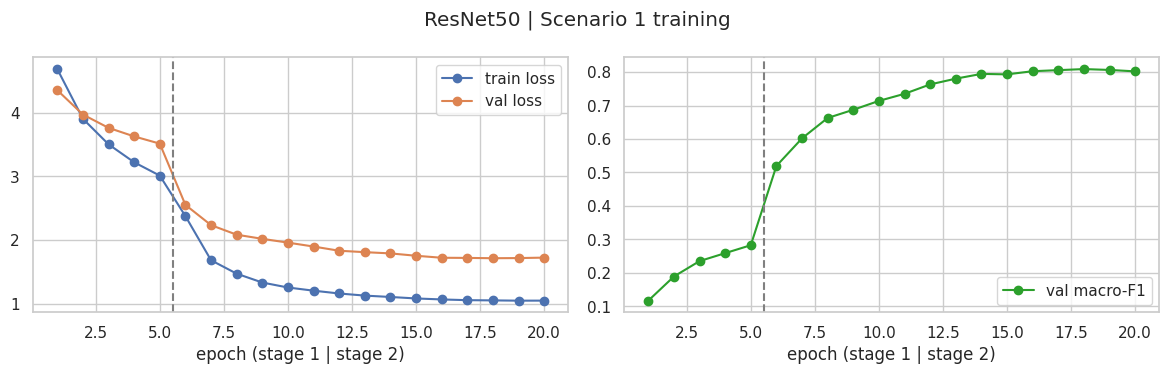

  public validation accuracy of the best epoch: 0.8092 | 6.7 min

MaxViT-Tiny | Scenario 1 (public -> private)
  stage 1: head only (364,228 trainable params)
    [stage 1] epoch 01 | lr 5.0e-04 | train 4.5779 | val 4.0895 | val acc 0.0999 | val macro-F1 0.0516  *best*
    [stage 1] epoch 02 | lr 5.0e-04 | train 3.9327 | val 3.8218 | val acc 0.1532 | val macro-F1 0.1135  *best*
    [stage 1] epoch 03 | lr 5.0e-04 | train 3.6815 | val 3.6576 | val acc 0.2072 | val macro-F1 0.1599  *best*
    [stage 1] epoch 04 | lr 5.0e-04 | train 3.4727 | val 3.5213 | val acc 0.2523 | val macro-F1 0.2091  *best*
    [stage 1] epoch 05 | lr 5.0e-04 | train 3.3130 | val 3.3868 | val acc 0.2826 | val macro-F1 0.2368  *best*
  stage 2: stages 3-4 (blocks.2, blocks.3) + new classifier (29,060,372 trainable params)
    [stage 2] epoch 06 | lr 5.0e-05 | train 3.0383 | val 2.7232 | val acc 0.4791 | val macro-F1 0.4491  *best*
    [stage 2] epoch 07 | lr 4.9e-05 | train 2.3793 | val 2.2816 | val acc 0.6036 | va

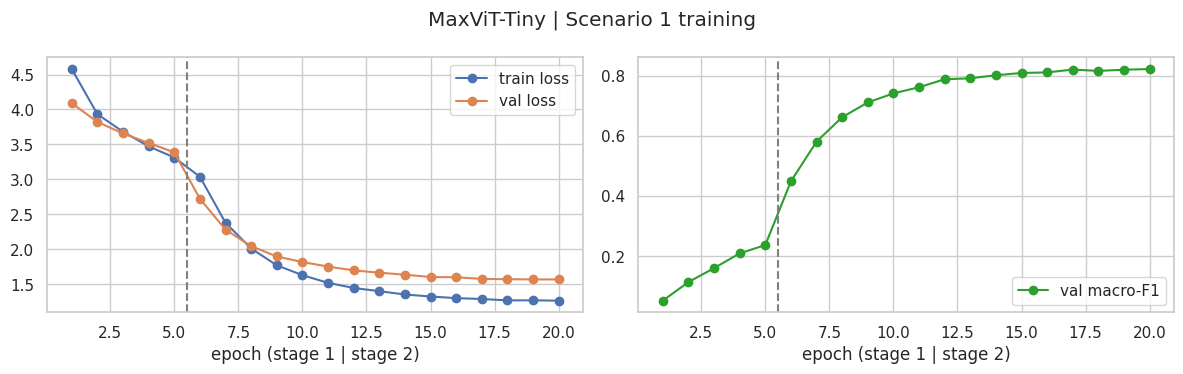

  public validation accuracy of the best epoch: 0.8264 | 17.8 min

ResNet50 | SCENARIO 1 (make level, 3 shared makes, 3495 private test images)
  Accuracy 0.4203 | F1 macro 0.4059 | F1 weighted 0.4263 | AUC (OvR macro) 0.6342 | balanced acc 0.4264
  (chance level for 3 makes ~ 0.33; majority-make baseline = 0.43)


,make,test_images,recall
0,honda,657,0.4247
1,suzuki,1512,0.3056
2,toyota,1326,0.5490


,pred honda,pred suzuki,pred toyota
true honda,279,121,257
true suzuki,607,462,443
true toyota,342,256,728


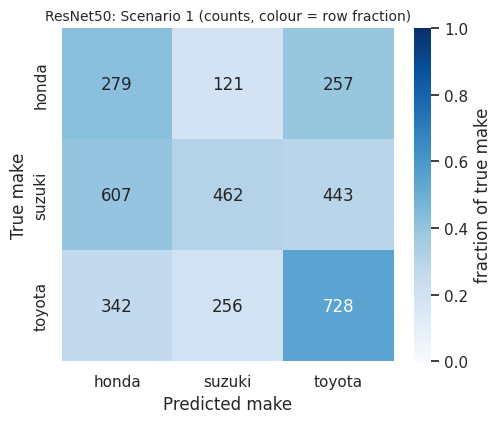

  Non-shared private makes: what the Stanford-trained model predicts most often (NOT included in the scores):


,private make (not scored),images,most predicted make,share,top-3 predictions
0,daihatsu,254,chevrolet,0.339,"chevrolet (86), dodge (39), volkswagen (34)"
1,faw,67,chevrolet,0.373,"chevrolet (25), ford (20), hyundai (7)"
2,kia,31,hyundai,0.387,"hyundai (12), chevrolet (7), buick (4)"



MaxViT-Tiny | SCENARIO 1 (make level, 3 shared makes, 3495 private test images)
  Accuracy 0.5471 | F1 macro 0.5195 | F1 weighted 0.5508 | AUC (OvR macro) 0.7105 | balanced acc 0.5231
  (chance level for 3 makes ~ 0.33; majority-make baseline = 0.43)


,make,test_images,recall
0,honda,657,0.4216
1,suzuki,1512,0.6078
2,toyota,1326,0.5400


,pred honda,pred suzuki,pred toyota
true honda,277,180,200
true suzuki,288,919,305
true toyota,228,382,716


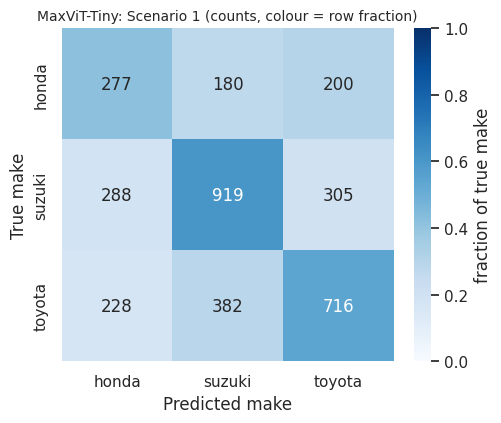

  Non-shared private makes: what the Stanford-trained model predicts most often (NOT included in the scores):


,private make (not scored),images,most predicted make,share,top-3 predictions
0,daihatsu,254,volkswagen,0.390,"volkswagen (99), chevrolet (55), ford (44)"
1,faw,67,ford,0.209,"ford (14), mercedes-benz (12), hyundai (10)"
2,kia,31,volkswagen,0.258,"volkswagen (8), chevrolet (7), nissan (5)"


,model,acc,bal_acc,f1_macro,f1_weighted,prec_macro,rec_macro,auc_ovr_macro
0,ResNet50,0.4203,0.4264,0.4059,0.4263,0.4292,0.4264,0.6342
1,MaxViT-Tiny,0.5471,0.5231,0.5195,0.5508,0.5187,0.5231,0.7105


In [17]:
if 1 in SCENARIOS_TO_RUN and SHARED_MAKES:
    run_scenario1()
    report_scenario1()
else:
    print("Scenario 1 skipped (not in SCENARIOS_TO_RUN or no shared makes).")

---
## 7. SCENARIO 2: 10-fold cross-validation on the private data only
`StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)` on the merged private pool.
For every fold and model: the training part is split into train / validation (stratified), balancing and augmentation are computed from the **training part only**,
the model is trained with two-stage transfer learning, and it is tested on the held-out fold. Each finished fold is saved to disk (`RESUME` skips it next time).

The runner below is shared with Scenario 3.

In [18]:
def run_cv(scn, pool_df, title):
    out_root = RES / scn; out_root.mkdir(parents=True, exist_ok=True)
    pool = pool_df.reset_index(drop=True).copy()
    classes = sorted(pool["label"].unique()); cid = {c: i for i, c in enumerate(classes)}
    pool["label_id"] = pool["label"].map(cid)
    num_classes = len(classes)
    (out_root / "classes.json").write_text(json.dumps(classes))
    folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(pool)), pool["label_id"]))
    print(f"{title}: {len(pool)} images, {num_classes} classes, {N_FOLDS} folds")
    for arch in RUN_ARCHS:
        d = out_root / arch; d.mkdir(exist_ok=True)
        done_times = []; t_arch = time.time()
        for k, (tr, te) in enumerate(folds, 1):
            jf, nf = d / f"fold_{k:02d}.json", d / f"fold_{k:02d}.npz"
            if RESUME and jf.exists() and nf.exists() and np.array_equal(np.load(nf)["test_idx"], te):
                print(f"[{ARCH_INFO[arch]['title']}] fold {k}/{N_FOLDS}: saved result found -> skipped"); continue
            t0 = time.time()
            print(f"\n{'=' * 78}\n{ARCH_INFO[arch]['title']} | {title} | fold {k}/{N_FOLDS}\n{'=' * 78}")
            train_df, val_df = split_train_val(pool.iloc[tr])
            test_df = pool.iloc[te].reset_index(drop=True)
            run = train_one_run(arch, train_df, val_df, num_classes, f"{scn}_{arch}_f{k}")
            y_true, y_pred, probs = evaluate(run["model"], test_df, num_classes)
            met, skipped = compute_all(y_true, y_pred, probs)
            np.savez_compressed(nf, test_idx=te, y_true=y_true, y_pred=y_pred, probs=probs,
                                source=test_df["source"].values.astype(str))
            minutes = (time.time() - t0) / 60
            jf.write_text(json.dumps(dict(fold=k, arch=arch, n_train=len(train_df), n_val=len(val_df), n_test=len(test_df),
                                          best_val_macro_f1=run["best_val_f1"], epochs_run=run["epochs_run"], minutes=minutes,
                                          metrics=met, auc_skipped=skipped), indent=1))
            done_times.append(minutes); left = N_FOLDS - k
            print(f"  >>> fold {k} TEST: acc {met['acc']:.4f} | F1-macro {met['f1_macro']:.4f} | F1-weighted {met['f1_weighted']:.4f} | "
                  f"AUC {met['auc_ovr_macro']:.4f} | best val F1 {run['best_val_f1']:.4f}")
            print(f"  >>> AUC skipped (class absent in this test fold): {describe_skipped(skipped, classes)}")
            print(f"  >>> time for this fold {minutes:.1f} min | average {np.mean(done_times):.1f} min | "
                  f"ETA for the remaining {left} folds of this model: {np.mean(done_times) * left:.0f} min")
            del run; torch.cuda.empty_cache()
        print(f"\n[{ARCH_INFO[arch]['title']}] {title}: finished in {(time.time() - t_arch) / 60:.1f} min this session")


def load_cv(scn, arch):
    files = sorted((RES / scn / arch).glob("fold_*.json"))
    recs = [json.loads(f.read_text()) for f in files]
    arrs = []
    for f in files:
        z = np.load(f.with_suffix(".npz")); arrs.append({k: z[k] for k in z.files})
    return recs, arrs


def report_cv(scn, title):
    cls_file = RES / scn / "classes.json"
    if not cls_file.exists():
        print(f"{title}: no results yet."); return
    classes = json.loads(cls_file.read_text())
    for arch in RUN_ARCHS:
        recs, arrs = load_cv(scn, arch)
        if not recs:
            print(f"[{arch}] no folds finished for {title}"); continue
        name = ARCH_INFO[arch]["title"]
        print(f"\n{'=' * 78}\n{name} | {title} | {len(recs)}/{N_FOLDS} folds\n{'=' * 78}")
        if len(recs) < N_FOLDS:
            print("  WARNING: not all folds are finished; the numbers below cover the finished folds only.")
        tbl = pd.DataFrame([{"fold": r["fold"], "n_test": r["n_test"], **r["metrics"], "best_val_F1": r["best_val_macro_f1"],
                             "epochs": r["epochs_run"], "minutes": r["minutes"]} for r in recs])
        tbl.to_csv(RES / scn / f"{arch}_folds.csv", index=False)
        display(tbl.round(4))
        ms = mean_std_table(tbl, METRIC_KEYS); print("per-fold mean and std:"); display(ms.round(4))
        # ---- pooled out-of-fold ----
        yt, yp = np.concatenate([a["y_true"] for a in arrs]), np.concatenate([a["y_pred"] for a in arrs])
        pr, src = np.concatenate([a["probs"] for a in arrs]), np.concatenate([a["source"] for a in arrs])
        pooled, skipped = compute_all(yt, yp, pr)
        print(f"POOLED out-of-fold ({len(yt)} images predicted once each): " +
              " | ".join(f"{k} {pooled[k]:.4f}" for k in ("acc", "f1_macro", "f1_weighted", "auc_ovr_macro")))
        print(f"  AUC skipped (absent from all test folds): {describe_skipped(skipped, classes)}")
        (RES / scn / f"{arch}_pooled.json").write_text(json.dumps(dict(
            metrics=pooled, n=int(len(yt)), n_folds=len(recs), auc_skipped=[classes[c] for c in skipped],
            mean={k: float(ms.loc["mean", k]) for k in METRIC_KEYS}, std={k: float(ms.loc["std", k]) for k in METRIC_KEYS}), indent=1))
        # ---- confusion matrix + per-class report ----
        labels = np.arange(len(classes))
        cm = confusion_matrix(yt, yp, labels=labels)
        pd.DataFrame(cm, index=classes, columns=classes).to_csv(RES / scn / f"{arch}_confusion_matrix_full.csv")
        rep = pd.DataFrame(classification_report(yt, yp, labels=labels, target_names=classes, output_dict=True, zero_division=0)).T
        rep.to_csv(RES / scn / f"{arch}_per_class_report.csv")
        plot_confusion_top(cm, classes, 30, f"{name} | {title}: pooled confusion matrix (top-30 most confused classes)",
                           f"{scn}_{arch}_confusion_top30.png")
        worst = rep.iloc[:len(classes)].sort_values("f1-score").head(5)
        print("  5 hardest classes (lowest F1):", "; ".join(f"{i} ({r['f1-score']:.2f})" for i, r in worst.iterrows()))
        # ---- split by source (Scenario 3) ----
        if scn == "s3":
            rows = []
            for s in ("public", "private"):
                per_fold = []
                for a in arrs:
                    m = a["source"] == s
                    if m.sum() > 0:
                        per_fold.append(compute_all(a["y_true"][m], a["y_pred"][m], a["probs"][m])[0])
                pf = pd.DataFrame(per_fold); m_all = src == s
                pooled_s, _ = compute_all(yt[m_all], yp[m_all], pr[m_all])
                row = {"part": s, "images": int(m_all.sum())}
                for k in ("acc", "f1_macro", "f1_weighted", "auc_ovr_macro"):
                    row[f"{k} (fold mean ± std)"] = f"{pf[k].mean():.4f} ± {pf[k].std(ddof=1):.4f}"
                    row[f"{k} pooled"] = round(pooled_s[k], 4)
                rows.append(row)
            by_src = pd.DataFrame(rows)
            print("Metrics split by source (part of each test fold that came from the public / private dataset):")
            display(by_src); by_src.to_csv(RES / scn / f"{arch}_by_source.csv", index=False)

Scenario 2 (private only): 3847 images, 48 classes, 10 folds

ResNet50 | Scenario 2 (private only) | fold 1/10
  stage 1: head only (98,352 trainable params)
    [stage 1] epoch 01 | lr 1.0e-03 | train 3.5878 | val 3.3844 | val acc 0.2375 | val macro-F1 0.1516  *best*
    [stage 1] epoch 02 | lr 1.0e-03 | train 3.1179 | val 3.1300 | val acc 0.3745 | val macro-F1 0.2841  *best*
    [stage 1] epoch 03 | lr 1.0e-03 | train 2.8147 | val 2.9561 | val acc 0.4363 | val macro-F1 0.3840  *best*
    [stage 1] epoch 04 | lr 1.0e-03 | train 2.6069 | val 2.7866 | val acc 0.4498 | val macro-F1 0.4124  *best*
    [stage 1] epoch 05 | lr 1.0e-03 | train 2.4617 | val 2.6643 | val acc 0.4961 | val macro-F1 0.4533  *best*
  stage 2: layer3 + layer4 + new fc (22,161,456 trainable params)
    [stage 2] epoch 06 | lr 1.0e-04 | train 1.9052 | val 1.4976 | val acc 0.8050 | val macro-F1 0.7444  *best*
    [stage 2] epoch 07 | lr 9.9e-05 | train 1.1909 | val 1.2027 | val acc 0.8745 | val macro-F1 0.8374  *best*

,fold,n_test,acc,bal_acc,f1_macro,f1_weighted,prec_macro,rec_macro,auc_ovr_macro,best_val_F1,epochs,minutes
0,1,385,0.9532,0.9218,0.9312,0.9514,0.9547,0.9218,0.9987,0.9309,19,2.9649
1,2,385,0.9455,0.8951,0.8893,0.9410,0.8998,0.8951,0.9975,0.9260,18,2.7695
2,3,385,0.9610,0.9237,0.9348,0.9598,0.9581,0.9237,0.9991,0.9217,20,3.0987
3,4,385,0.9584,0.9202,0.9245,0.9558,0.9405,0.9202,0.9981,0.9365,18,2.7688
4,5,385,0.9377,0.8952,0.8998,0.9341,0.9212,0.8952,0.9969,0.9378,20,3.0993
5,6,385,0.9558,0.9420,0.9444,0.9547,0.9603,0.9420,0.9965,0.9378,20,3.1025
6,7,385,0.9377,0.9236,0.9192,0.9365,0.9403,0.9236,0.9982,0.9321,18,2.7632
7,8,384,0.9505,0.9255,0.9279,0.9497,0.9500,0.9255,0.9944,0.9363,20,3.1362
8,9,384,0.9349,0.9260,0.9262,0.9339,0.9392,0.9260,0.9986,0.8844,12,1.7780
9,10,384,0.9635,0.9301,0.9320,0.9600,0.9451,0.9301,0.9976,0.9279,20,3.1383


per-fold mean and std:


,acc,bal_acc,f1_macro,f1_weighted,prec_macro,rec_macro,auc_ovr_macro
mean,0.9498,0.9203,0.9229,0.9477,0.9409,0.9203,0.9976
std,0.0104,0.0146,0.0166,0.0104,0.0184,0.0146,0.0014


POOLED out-of-fold (3847 images predicted once each): acc 0.9498 | f1_macro 0.9269 | f1_weighted 0.9490 | auc_ovr_macro 0.9974
  AUC skipped (absent from all test folds): none


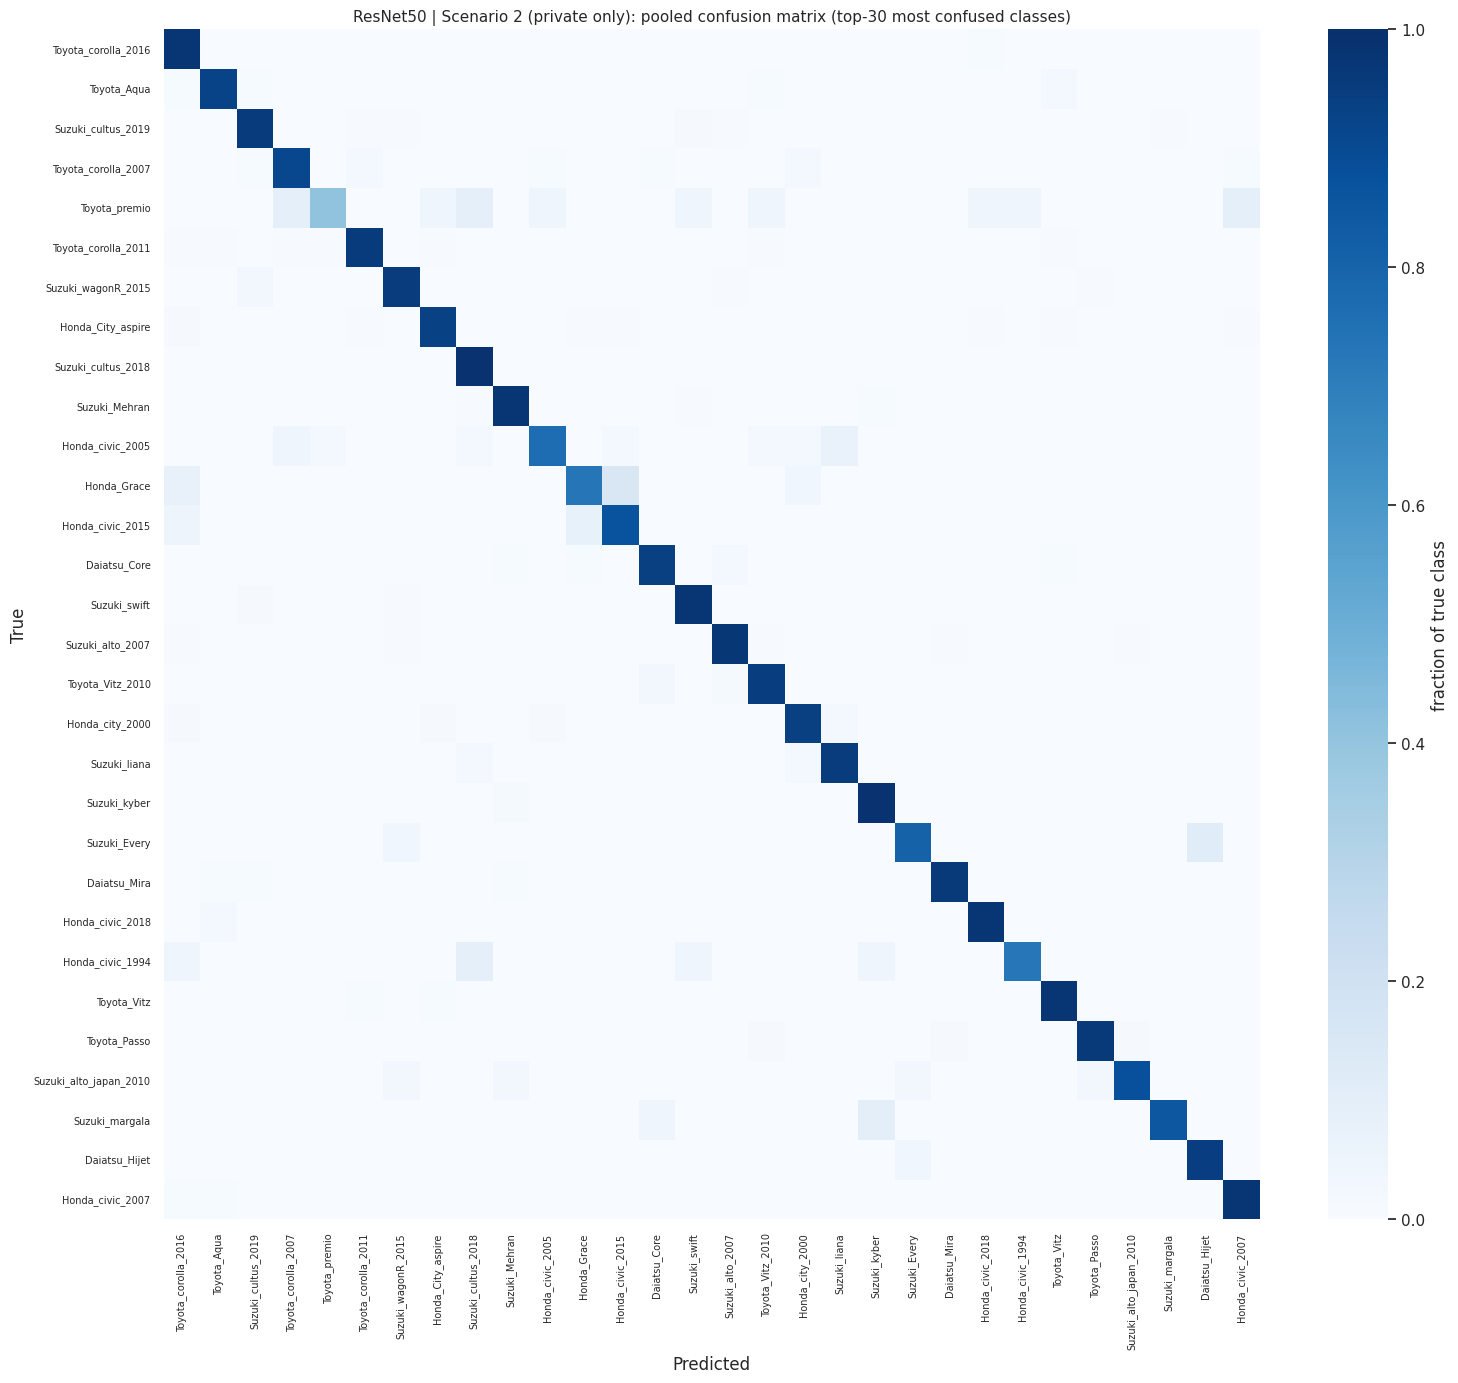

  5 hardest classes (lowest F1): Toyota_premio (0.55); Honda_Grace (0.76); Honda_civic_1994 (0.82); Honda_civic_2005 (0.83); Suzuki_Every (0.84)

MaxViT-Tiny | Scenario 2 (private only) | 10/10 folds


,fold,n_test,acc,bal_acc,f1_macro,f1_weighted,prec_macro,rec_macro,auc_ovr_macro,best_val_F1,epochs,minutes
0,1,385,0.9636,0.9284,0.9357,0.9617,0.9570,0.9284,0.9996,0.9284,20,7.9074
1,2,385,0.9403,0.8944,0.8908,0.9351,0.8952,0.8944,0.9986,0.9267,20,7.7414
2,3,385,0.9532,0.9211,0.9235,0.9516,0.9403,0.9211,0.9974,0.9323,20,7.7261
3,4,385,0.9584,0.9289,0.9328,0.9585,0.9514,0.9289,0.9971,0.9339,19,7.3210
4,5,385,0.9325,0.8901,0.8852,0.9297,0.9049,0.8901,0.9951,0.9180,20,7.7416
5,6,385,0.9532,0.9294,0.9298,0.9523,0.9407,0.9294,0.9988,0.9252,20,7.7920
6,7,385,0.9584,0.9507,0.9457,0.9578,0.9601,0.9507,0.9985,0.9295,20,7.7579
7,8,384,0.9453,0.9225,0.9254,0.9442,0.9475,0.9225,0.9950,0.9392,18,6.9631
8,9,384,0.9635,0.9634,0.9582,0.9638,0.9567,0.9634,0.9993,0.9256,20,7.8163
9,10,384,0.9661,0.9333,0.9326,0.9640,0.9424,0.9333,0.9955,0.9264,20,7.8043


per-fold mean and std:


,acc,bal_acc,f1_macro,f1_weighted,prec_macro,rec_macro,auc_ovr_macro
mean,0.9535,0.9262,0.9260,0.9519,0.9396,0.9262,0.9975
std,0.0110,0.0221,0.0225,0.0120,0.0221,0.0221,0.0017


POOLED out-of-fold (3847 images predicted once each): acc 0.9535 | f1_macro 0.9292 | f1_weighted 0.9530 | auc_ovr_macro 0.9973
  AUC skipped (absent from all test folds): none


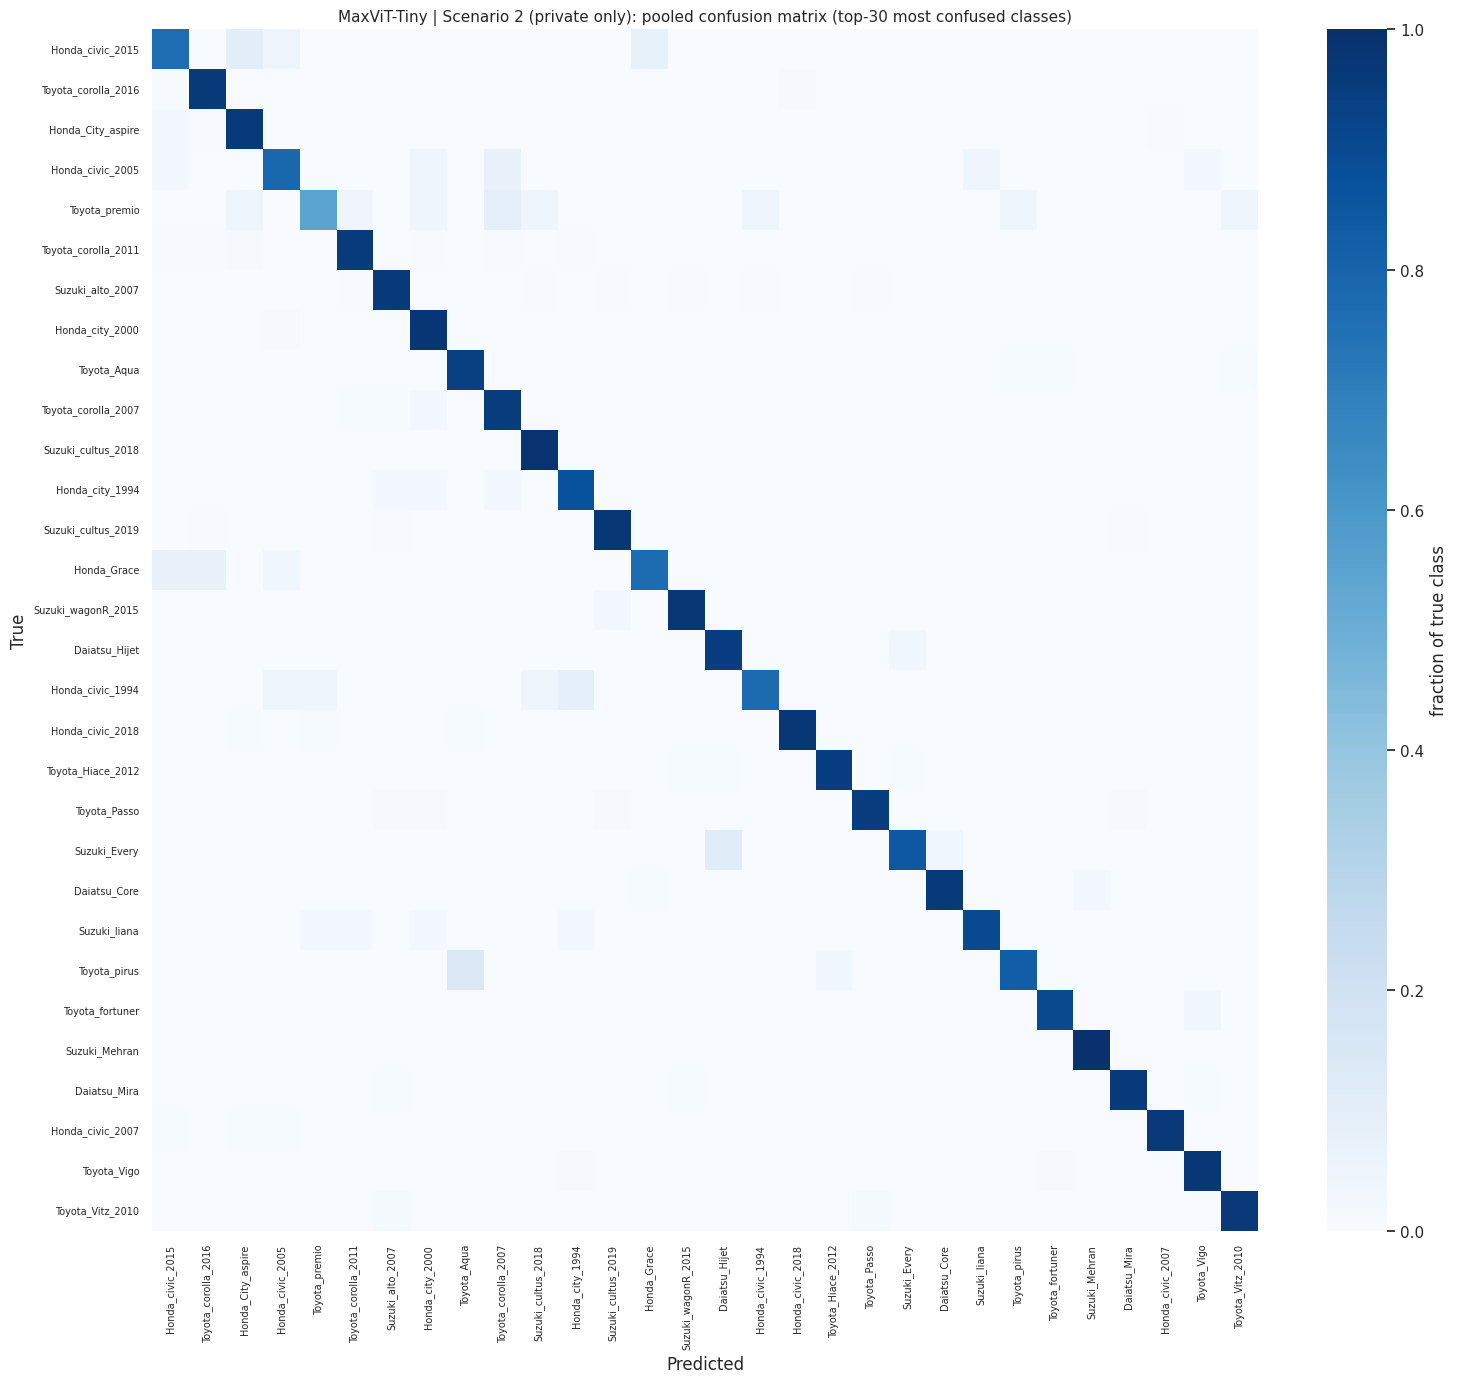

  5 hardest classes (lowest F1): Toyota_premio (0.63); Honda_civic_2015 (0.75); Honda_Grace (0.80); Honda_civic_1994 (0.81); Honda_civic_2005 (0.81)


In [19]:
if 2 in SCENARIOS_TO_RUN:
    S2_POOL = cap_per_class(PRIV_S2, MAX_PER_CLASS)
    run_cv("s2", S2_POOL, "Scenario 2 (private only)")
    report_cv("s2", "Scenario 2 (private only)")
else:
    print("Scenario 2 skipped (not in SCENARIOS_TO_RUN).")

---
## 8. SCENARIO 3: 10-fold cross-validation on public + private combined
Stanford Cars (196 classes) and the private set (48 classes) are put into one table with a `source` column.
**No labels are merged**: the 196 + 48 = 244 classes keep their own identity (the label is prefixed with `public|` or `private|`, so equal names can never collide).
`StratifiedKFold(10)` is stratified by this class label; the procedure per fold is the same as in Scenario 2.
The private part is the cleaned set (cross-dataset duplicates removed). `MAX_PER_CLASS` is applied if set.
Besides the overall metrics, we report the metrics **separately for the public part and the private part** of the test folds, and the pooled out-of-fold metrics.
The full 244x244 confusion matrix is saved as a CSV; only the 30 most confused classes are plotted.

Combined pool: 11991 images | classes: 244 (public 196 + private 48) | no label merging
  estimated Scenario 3 time for ResNet50: 1.4 h
  estimated Scenario 3 time for MaxViT-Tiny: 4.0 h
Scenario 3 (public + private): 11991 images, 244 classes, 10 folds

ResNet50 | Scenario 3 (public + private) | fold 1/10
  stage 1: head only (499,956 trainable params)
    [stage 1] epoch 01 | lr 1.0e-03 | train 4.7423 | val 4.3386 | val acc 0.1420 | val macro-F1 0.1155  *best*
    [stage 1] epoch 02 | lr 1.0e-03 | train 3.8396 | val 3.9199 | val acc 0.2790 | val macro-F1 0.2163  *best*
    [stage 1] epoch 03 | lr 1.0e-03 | train 3.4227 | val 3.6828 | val acc 0.3245 | val macro-F1 0.2629  *best*
    [stage 1] epoch 04 | lr 1.0e-03 | train 3.1190 | val 3.5229 | val acc 0.3589 | val macro-F1 0.3062  *best*
    [stage 1] epoch 05 | lr 1.0e-03 | train 2.9037 | val 3.4009 | val acc 0.3872 | val macro-F1 0.3210  *best*
  stage 2: layer3 + layer4 + new fc (22,563,060 trainable params)
    [stage 2] epoch 06 

,fold,n_test,acc,bal_acc,f1_macro,f1_weighted,prec_macro,rec_macro,auc_ovr_macro,best_val_F1,epochs,minutes
0,1,1200,0.8450,0.8228,0.8176,0.8405,0.8361,0.8228,0.9949,0.7996,20,8.9128
1,2,1199,0.8624,0.8362,0.8351,0.8612,0.8683,0.8362,0.9977,0.8196,20,8.8961
2,3,1199,0.8365,0.8087,0.8087,0.8325,0.8461,0.8087,0.9975,0.8138,20,8.9307
3,4,1199,0.8549,0.8311,0.8292,0.8527,0.8550,0.8311,0.9981,0.8357,20,8.9134
4,5,1199,0.8549,0.8291,0.8272,0.8508,0.8545,0.8291,0.9967,0.8426,20,8.9067
5,6,1199,0.8407,0.8168,0.8079,0.8333,0.8335,0.8168,0.9974,0.8164,20,8.9115
6,7,1199,0.8349,0.8107,0.8077,0.8308,0.8404,0.8107,0.9975,0.8338,20,8.9290
7,8,1199,0.8382,0.8088,0.8027,0.8319,0.8306,0.8088,0.9977,0.8146,20,8.9091
8,9,1199,0.8440,0.8120,0.8077,0.8385,0.8409,0.8120,0.9965,0.8079,20,8.9127
9,10,1199,0.8557,0.8282,0.8242,0.8515,0.8527,0.8282,0.9977,0.8089,20,8.8989


per-fold mean and std:


,acc,bal_acc,f1_macro,f1_weighted,prec_macro,rec_macro,auc_ovr_macro
mean,0.8467,0.8204,0.8168,0.8424,0.8458,0.8204,0.9972
std,0.0096,0.0103,0.0114,0.0109,0.0117,0.0103,0.0009


POOLED out-of-fold (11991 images predicted once each): acc 0.8467 | f1_macro 0.8218 | f1_weighted 0.8460 | auc_ovr_macro 0.9970
  AUC skipped (absent from all test folds): none


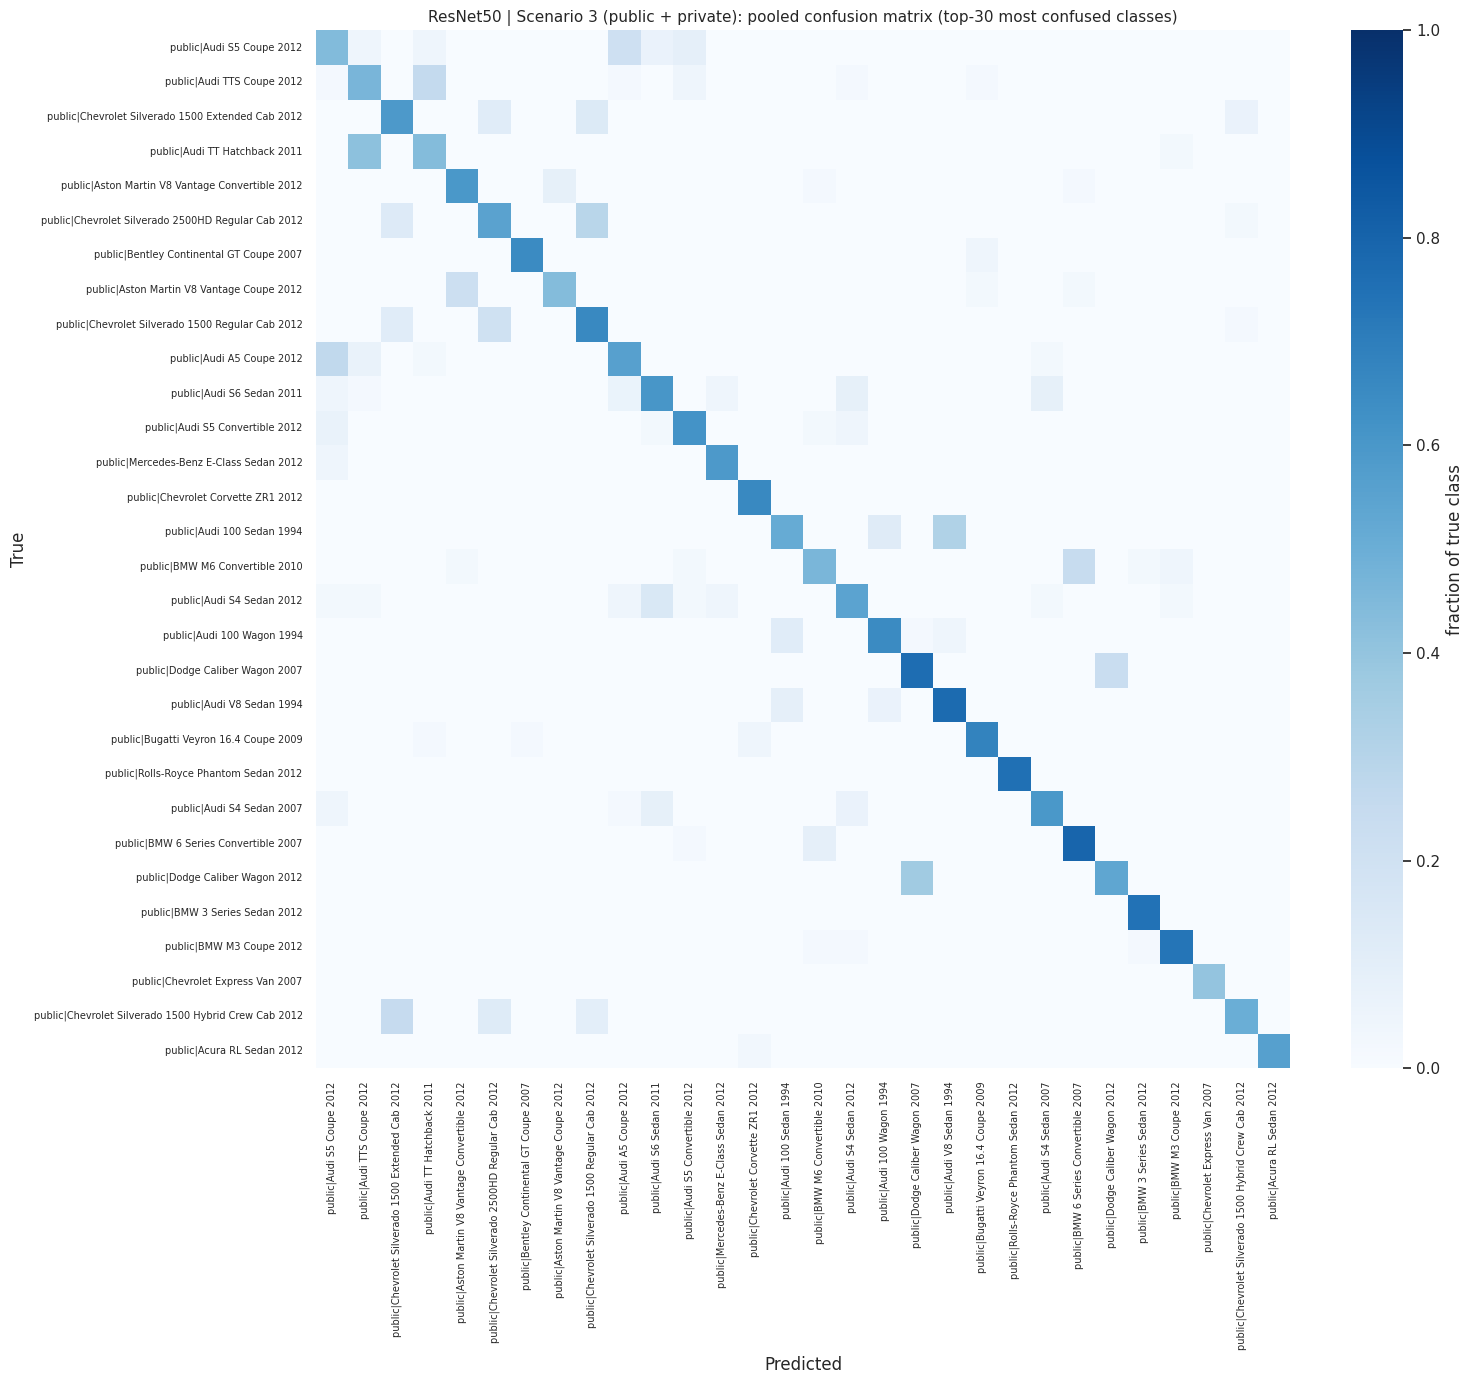

  5 hardest classes (lowest F1): public|Audi S5 Coupe 2012 (0.40); public|Audi TTS Coupe 2012 (0.43); public|Audi TT Hatchback 2011 (0.45); public|Aston Martin V8 Vantage Coupe 2012 (0.49); public|Chevrolet Silverado 2500HD Regular Cab 2012 (0.49)
Metrics split by source (part of each test fold that came from the public / private dataset):


,part,images,acc (fold mean ± std),acc pooled,f1_macro (fold mean ± std),f1_macro pooled,f1_weighted (fold mean ± std),f1_weighted pooled,auc_ovr_macro (fold mean ± std),auc_ovr_macro pooled
0,public,8144,0.7983 ± 0.0147,0.7983,0.7831 ± 0.0140,0.7282,0.7939 ± 0.0170,0.7990,0.9960 ± 0.0007,0.9958
1,private,3847,0.9493 ± 0.0110,0.9493,0.8939 ± 0.0111,0.7142,0.9493 ± 0.0111,0.9502,0.9971 ± 0.0038,0.9968



MaxViT-Tiny | Scenario 3 (public + private) | 10/10 folds


,fold,n_test,acc,bal_acc,f1_macro,f1_weighted,prec_macro,rec_macro,auc_ovr_macro,best_val_F1,epochs,minutes
0,1,1200,0.8650,0.8432,0.8363,0.8594,0.8612,0.8432,0.9983,0.8287,20,23.5300
1,2,1199,0.8799,0.8576,0.8524,0.8757,0.8776,0.8576,0.9988,0.8529,20,23.4774
2,3,1199,0.8590,0.8357,0.8320,0.8556,0.8628,0.8357,0.9989,0.8424,20,23.3999
3,4,1199,0.8824,0.8631,0.8621,0.8795,0.8863,0.8631,0.9994,0.8594,20,23.5118
4,5,1199,0.8616,0.8391,0.8387,0.8587,0.8744,0.8391,0.9984,0.8396,20,23.3986
5,6,1199,0.8507,0.8270,0.8214,0.8447,0.8529,0.8270,0.9986,0.8467,20,23.4592
6,7,1199,0.8666,0.8458,0.8420,0.8636,0.8734,0.8458,0.9989,0.8568,20,23.3914
7,8,1199,0.8582,0.8323,0.8314,0.8544,0.8612,0.8323,0.9989,0.8552,20,23.4443
8,9,1199,0.8716,0.8435,0.8433,0.8685,0.8826,0.8435,0.9984,0.8344,20,23.4548
9,10,1199,0.8774,0.8542,0.8524,0.8754,0.8834,0.8542,0.9991,0.8532,20,23.4540


per-fold mean and std:


,acc,bal_acc,f1_macro,f1_weighted,prec_macro,rec_macro,auc_ovr_macro
mean,0.8672,0.8442,0.8412,0.8635,0.8716,0.8442,0.9988
std,0.0104,0.0114,0.0120,0.0111,0.0114,0.0114,0.0003


POOLED out-of-fold (11991 images predicted once each): acc 0.8672 | f1_macro 0.8468 | f1_weighted 0.8674 | auc_ovr_macro 0.9987
  AUC skipped (absent from all test folds): none


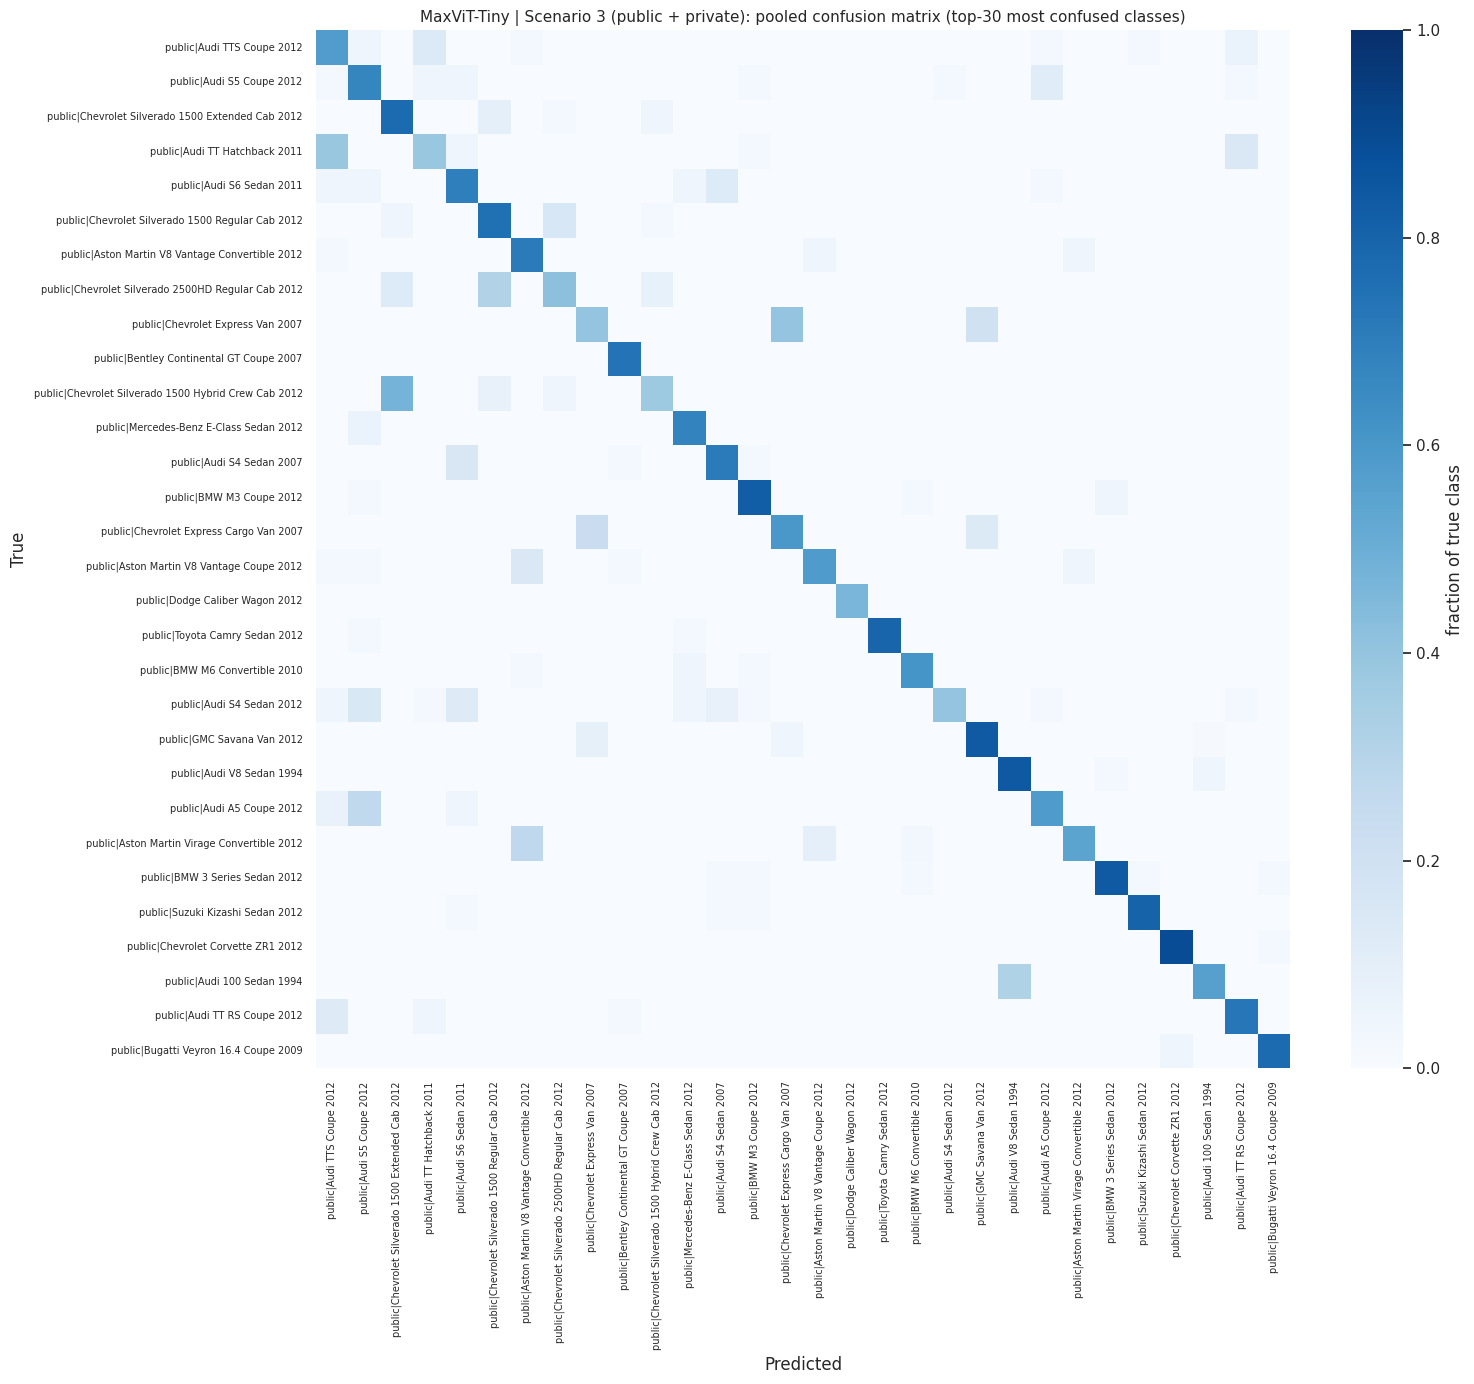

  5 hardest classes (lowest F1): public|Chevrolet Express Van 2007 (0.45); public|Audi TT Hatchback 2011 (0.46); public|Chevrolet Silverado 1500 Hybrid Crew Cab 2012 (0.48); public|Chevrolet Silverado 2500HD Regular Cab 2012 (0.48); public|Audi TTS Coupe 2012 (0.49)
Metrics split by source (part of each test fold that came from the public / private dataset):


,part,images,acc (fold mean ± std),acc pooled,f1_macro (fold mean ± std),f1_macro pooled,f1_weighted (fold mean ± std),f1_weighted pooled,auc_ovr_macro (fold mean ± std),auc_ovr_macro pooled
0,public,8144,0.8296 ± 0.0132,0.8296,0.8194 ± 0.0166,0.7858,0.8254 ± 0.0139,0.8306,0.9984 ± 0.0004,0.9983
1,private,3847,0.9470 ± 0.0121,0.9470,0.8845 ± 0.0335,0.6803,0.9474 ± 0.0120,0.9487,0.9975 ± 0.0017,0.9972


In [20]:
if 3 in SCENARIOS_TO_RUN:
    COMBINED = pd.concat([PUB_USE.assign(label="public|" + PUB_USE["label"]),
                          PRIV_S13.assign(label="private|" + PRIV_S13["label"])], ignore_index=True)
    S3_POOL = cap_per_class(COMBINED, MAX_PER_CLASS)
    print(f"Combined pool: {len(S3_POOL)} images | classes: {S3_POOL['label'].nunique()} "
          f"(public {S3_POOL[S3_POOL.source == 'public']['label'].nunique()} + private {S3_POOL[S3_POOL.source == 'private']['label'].nunique()}) | no label merging")
    if not FAST_DEBUG:
        s3_min = {a: N_FOLDS * est_minutes(a, len(S3_POOL) * (1 - 1 / N_FOLDS) * (1 - VAL_FRACTION),
                                           len(S3_POOL) * (1 - 1 / N_FOLDS) * VAL_FRACTION, len(S3_POOL) / N_FOLDS) for a in RUN_ARCHS}
        for a, mins in s3_min.items():
            print(f"  estimated Scenario 3 time for {ARCH_INFO[a]['title']}: {mins / 60:.1f} h")
        if sum(s3_min.values()) / 60 > SESSION_LIMIT_H:
            print(f"  WARNING: Scenario 3 alone for {RUN_ARCHS} is longer than one Kaggle session (~{SESSION_LIMIT_H:.0f} h). "
                  "Run one model per session (RUN_ARCHS), set MAX_PER_CLASS (e.g. 60), and keep RESUME = True so finished folds are not repeated.")
    run_cv("s3", S3_POOL, "Scenario 3 (public + private)")
    report_cv("s3", "Scenario 3 (public + private)")
else:
    print("Scenario 3 skipped (not in SCENARIOS_TO_RUN).")

---
## 9. Final results
All numbers are read back from the saved result files, so they also work after a restart or when the two models were run in different sessions.
For Scenarios 2 and 3 each cell shows **fold mean ± std (pooled out-of-fold value)**; Scenario 1 is a single run.

In [21]:
SCN_LABEL = {"s1": "Scenario 1: public -> private (make level)", "s2": "Scenario 2: private only (10-fold CV)",
             "s3": "Scenario 3: public + private (10-fold CV)"}
SUMMARY_KEYS = ["acc", "f1_macro", "f1_weighted", "auc_ovr_macro"]
KEY_NAME = {"acc": "Accuracy", "f1_macro": "F1-macro", "f1_weighted": "F1-weighted", "auc_ovr_macro": "AUC (OvR macro)"}


def collect_summary():
    rows = []
    for scn in ("s1", "s2", "s3"):
        for arch in ARCHS:
            row = {"scenario": scn, "arch": arch, "model": ARCH_INFO[arch]["title"]}
            if scn == "s1":
                f = RES / "s1" / arch / "scores.json"
                if not f.exists(): continue
                m = json.loads(f.read_text())["metrics"]
                for k in SUMMARY_KEYS:
                    row.update({f"{k}_mean": m[k], f"{k}_std": np.nan, f"{k}_pooled": m[k]})
                row["folds"] = 1
            else:
                f = RES / scn / f"{arch}_pooled.json"
                if not f.exists(): continue
                p = json.loads(f.read_text())
                for k in SUMMARY_KEYS:
                    row.update({f"{k}_mean": p["mean"][k], f"{k}_std": p["std"][k], f"{k}_pooled": p["metrics"][k]})
                row["folds"] = p["n_folds"]
            rows.append(row)
    return pd.DataFrame(rows)


SUMMARY = collect_summary()
if SUMMARY.empty:
    print("No results found yet. Run sections 6-8 first.")
else:
    SUMMARY.to_csv(RES / "final_summary_numeric.csv", index=False)
    pretty = []
    for _, r in SUMMARY.iterrows():
        row = {"Scenario": SCN_LABEL[r.scenario], "Model": r.model, "folds": int(r.folds)}
        for k in SUMMARY_KEYS:
            row[KEY_NAME[k]] = (f"{r[k + '_mean']:.4f}" if np.isnan(r[k + "_std"])
                                else f"{r[k + '_mean']:.4f} ± {r[k + '_std']:.4f}  (pooled {r[k + '_pooled']:.4f})")
        pretty.append(row)
    PRETTY = pd.DataFrame(pretty); PRETTY.to_csv(RES / "final_summary_table.csv", index=False)
    pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 220)
    display(PRETTY)

,Scenario,Model,folds,Accuracy,F1-macro,F1-weighted,AUC (OvR macro)
0,Scenario 1: public -> private (make level),ResNet50,1,0.4203,0.4059,0.4263,0.6342
1,Scenario 1: public -> private (make level),MaxViT-Tiny,1,0.5471,0.5195,0.5508,0.7105
2,Scenario 2: private only (10-fold CV),ResNet50,10,0.9498 ± 0.0104 (pooled 0.9498),0.9229 ± 0.0166 (pooled 0.9269),0.9477 ± 0.0104 (pooled 0.9490),0.9976 ± 0.0014 (pooled 0.9974)
3,Scenario 2: private only (10-fold CV),MaxViT-Tiny,10,0.9535 ± 0.0110 (pooled 0.9535),0.9260 ± 0.0225 (pooled 0.9292),0.9519 ± 0.0120 (pooled 0.9530),0.9975 ± 0.0017 (pooled 0.9973)
4,Scenario 3: public + private (10-fold CV),ResNet50,10,0.8467 ± 0.0096 (pooled 0.8467),0.8168 ± 0.0114 (pooled 0.8218),0.8424 ± 0.0109 (pooled 0.8460),0.9972 ± 0.0009 (pooled 0.9970)
5,Scenario 3: public + private (10-fold CV),MaxViT-Tiny,10,0.8672 ± 0.0104 (pooled 0.8672),0.8412 ± 0.0120 (pooled 0.8468),0.8635 ± 0.0111 (pooled 0.8674),0.9988 ± 0.0003 (pooled 0.9987)


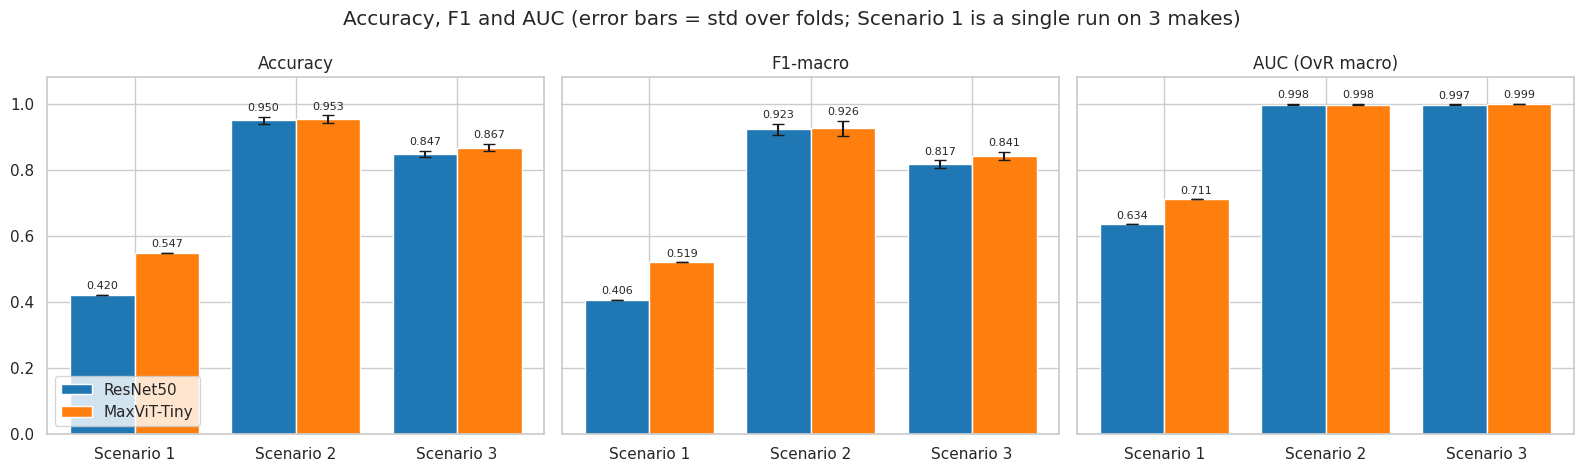

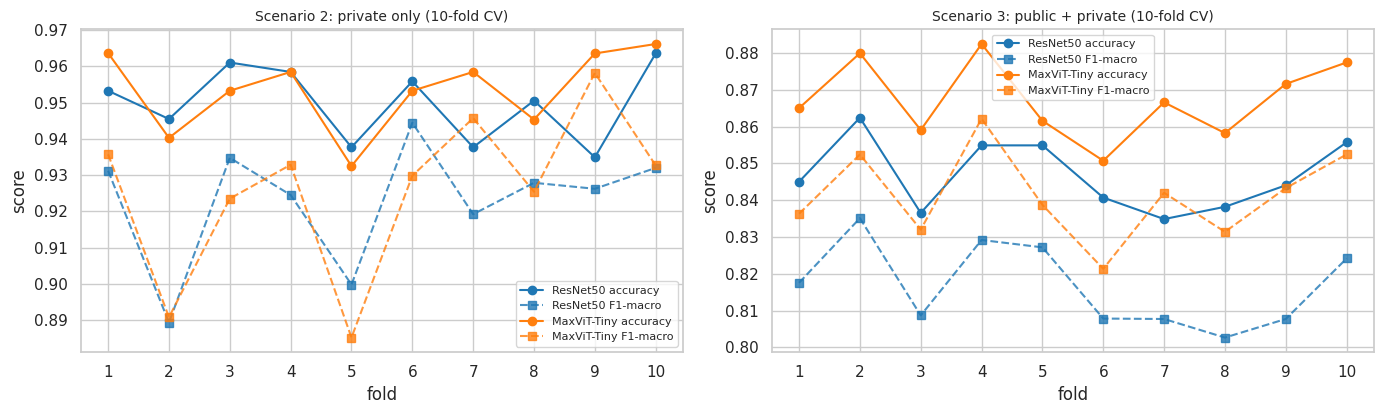

In [22]:
if not SUMMARY.empty:
    # ---------- grouped bar chart with error bars (std over folds; Scenario 1 has none) ----------
    scn_order = [s for s in ("s1", "s2", "s3") if s in set(SUMMARY.scenario)]
    archs_present = [a for a in ARCHS if a in set(SUMMARY.arch)]
    colors = {"resnet50": "tab:blue", "maxvit_t": "tab:orange"}
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
    width = 0.8 / max(len(archs_present), 1)
    for ax, key in zip(axes, ["acc", "f1_macro", "auc_ovr_macro"]):
        for ai, arch in enumerate(archs_present):
            vals, errs = [], []
            for s in scn_order:
                r = SUMMARY[(SUMMARY.scenario == s) & (SUMMARY.arch == arch)]
                vals.append(float(r[f"{key}_mean"].iloc[0]) if len(r) else np.nan)
                errs.append(float(np.nan_to_num(r[f"{key}_std"].iloc[0])) if len(r) else 0.0)
            xs = np.arange(len(scn_order)) + ai * width - 0.4 + width / 2
            bars = ax.bar(xs, vals, width, yerr=errs, capsize=4, color=colors.get(arch), label=ARCH_INFO[arch]["title"])
            ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=3)
        ax.set_xticks(np.arange(len(scn_order))); ax.set_xticklabels([f"Scenario {s[1]}" for s in scn_order])
        ax.set_title(KEY_NAME[key]); ax.set_ylim(0, 1.08)
    axes[0].legend(loc="lower left"); fig.suptitle("Accuracy, F1 and AUC (error bars = std over folds; Scenario 1 is a single run on 3 makes)")
    save_fig(fig, "09_grouped_bar_chart.png")

    # ---------- per-fold line plot for scenarios 2 and 3 ----------
    cv_scn = [s for s in ("s2", "s3") if any((RES / s / a / "fold_01.json").exists() for a in ARCHS)]
    if cv_scn:
        fig, axes = plt.subplots(1, len(cv_scn), figsize=(7 * len(cv_scn), 4.3), squeeze=False)
        for ax, s in zip(axes[0], cv_scn):
            for arch in ARCHS:
                f = RES / s / f"{arch}_folds.csv"
                if not f.exists(): continue
                t = pd.read_csv(f)
                ax.plot(t["fold"], t["acc"], "o-", color=colors.get(arch), label=f"{ARCH_INFO[arch]['title']} accuracy")
                ax.plot(t["fold"], t["f1_macro"], "s--", color=colors.get(arch), alpha=0.8, label=f"{ARCH_INFO[arch]['title']} F1-macro")
            ax.set_xlabel("fold"); ax.set_ylabel("score"); ax.set_title(SCN_LABEL[s], fontsize=10); ax.legend(fontsize=8)
            ax.set_xticks(range(1, N_FOLDS + 1))
        save_fig(fig, "09_per_fold_lines.png")

### 9.1 Automatic summary (generated from the numbers above, nothing is hard-coded)

In [23]:
def auto_summary(S):
    lines = []
    get = lambda s, a, k, col="mean": (lambda r: float(r[f"{k}_{col}"].iloc[0]) if len(r) else np.nan)(S[(S.scenario == s) & (S.arch == a)])
    arch_list = [a for a in ARCHS if a in set(S.arch)]
    lines.append("MODEL COMPARISON (by F1-macro, with accuracy and AUC for context)")
    for s in ("s1", "s2", "s3"):
        have = [a for a in arch_list if len(S[(S.scenario == s) & (S.arch == a)])]
        if len(have) < 2:
            if have: lines.append(f"- {SCN_LABEL[s]}: only {ARCH_INFO[have[0]]['title']} finished, no comparison possible yet.")
            continue
        f1 = {a: get(s, a, "f1_macro") for a in have}; best = max(f1, key=f1.get); other = [a for a in have if a != best][0]
        gap = f1[best] - f1[other]
        std = max(np.nan_to_num(get(s, best, "f1_macro", "std")), np.nan_to_num(get(s, other, "f1_macro", "std")))
        verdict = ("the gap is larger than one fold-std, so it is likely a real difference" if s != "s1" and gap > std else
                   "the gap is within one fold-std, so the two models are statistically close" if s != "s1" else
                   "single run, so the gap has no error bar")
        lines.append(f"- {SCN_LABEL[s]}: {ARCH_INFO[best]['title']} is better, F1-macro {f1[best]:.3f} vs {f1[other]:.3f} (gap {gap:.3f}); "
                     f"accuracy {get(s, best, 'acc'):.3f} vs {get(s, other, 'acc'):.3f}, AUC {get(s, best, 'auc_ovr_macro'):.3f} vs {get(s, other, 'auc_ovr_macro'):.3f}. "
                     f"Note: {verdict}.")
    lines.append("\nDOMAIN SHIFT (Scenario 1 vs Scenarios 2 and 3, accuracy)")
    n_shared = len(SHARED_MAKES)
    for a in arch_list:
        a1 = get("s1", a, "acc")
        if np.isnan(a1): continue
        for s in ("s2", "s3"):
            a2 = get(s, a, "acc")
            if not np.isnan(a2):
                lines.append(f"- {ARCH_INFO[a]['title']}: accuracy {a2:.3f} in {SCN_LABEL[s].split(':')[0]} -> {a1:.3f} in Scenario 1 "
                             f"(change {a1 - a2:+.3f}, i.e. {100 * (a1 - a2):+.1f} points).")
        f = RES / "s3" / f"{a}_by_source.csv"
        if f.exists():
            bs = pd.read_csv(f).set_index("part")
            if "private" in bs.index:
                lines.append(f"- {ARCH_INFO[a]['title']}: on the private part of Scenario 3 (the model has seen private-style images) pooled accuracy is "
                             f"{bs.loc['private', 'acc pooled']:.3f}, versus {a1:.3f} when only public images were used for training (Scenario 1).")
    def n_classes(scn):
        f = RES / scn / "classes.json"
        return len(json.loads(f.read_text())) if f.exists() else None
    lines.append(f"\nCAUTION: Scenario 1 is a {n_shared}-class make-level task (chance about {1 / max(n_shared, 1):.2f}), while Scenarios 2/3 have "
                 f"{n_classes('s2')} / {n_classes('s3')} classes. "
                 "The scores are therefore not directly comparable; a small accuracy change in Scenario 1 would hide a much larger loss of fine-grained "
                 "(model-level) information. The public data shows mostly US models of about 2012, the private data Pakistani models, which is the domain shift.")
    return "\n".join(lines)


SUMMARY_TEXT = auto_summary(SUMMARY) if not SUMMARY.empty else "No results yet."
print(SUMMARY_TEXT)
(RES / "auto_summary.txt").write_text(SUMMARY_TEXT)

MODEL COMPARISON (by F1-macro, with accuracy and AUC for context)
- Scenario 1: public -> private (make level): MaxViT-Tiny is better, F1-macro 0.519 vs 0.406 (gap 0.114); accuracy 0.547 vs 0.420, AUC 0.711 vs 0.634. Note: single run, so the gap has no error bar.
- Scenario 2: private only (10-fold CV): MaxViT-Tiny is better, F1-macro 0.926 vs 0.923 (gap 0.003); accuracy 0.953 vs 0.950, AUC 0.998 vs 0.998. Note: the gap is within one fold-std, so the two models are statistically close.
- Scenario 3: public + private (10-fold CV): MaxViT-Tiny is better, F1-macro 0.841 vs 0.817 (gap 0.024); accuracy 0.867 vs 0.847, AUC 0.999 vs 0.997. Note: the gap is larger than one fold-std, so it is likely a real difference.

DOMAIN SHIFT (Scenario 1 vs Scenarios 2 and 3, accuracy)
- ResNet50: accuracy 0.950 in Scenario 2 -> 0.420 in Scenario 1 (change -0.530, i.e. -53.0 points).
- ResNet50: accuracy 0.847 in Scenario 3 -> 0.420 in Scenario 1 (change -0.426, i.e. -42.6 points).
- ResNet50: on the priv

1952

### 9.2 Save everything to `results.zip`

In [24]:
zip_path = WORK / ("results_debug.zip" if FAST_DEBUG else "results.zip")
n_files = 0
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(RES.rglob("*")):
        if f.is_file() and f.suffix != ".pt":
            zf.write(f, f.relative_to(RES.parent)); n_files += 1
for leftover in WORK.glob("ckpt_*.pt"):
    leftover.unlink()
print(f"saved {n_files} files to {zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB)")
print("Tables (CSV), figures (PNG), per-fold JSON/NPZ predictions and the auto summary are inside.")

if FAST_DEBUG:
    print("\n*** SMOKE TEST PASSED: every section ran end-to-end in FAST_DEBUG mode. ***")

saved 137 files to /kaggle/working/results.zip (28.8 MB)
Tables (CSV), figures (PNG), per-fold JSON/NPZ predictions and the auto summary are inside.
